# Does Behavioural Stability Precede Mechanistic Stability During Small-Model Training?

**By: Hamda Aden**

This notebook trains a small GPT-2-style transformer (JAX/Flax) from scratch across multiple
random seeds, tracking **in-context learning (induction)** as it emerges during training. At each
checkpoint we measure two things:

1. **Behavioural signal** — a few-shot copying/induction eval score (does the model use context to
   predict repeated tokens correctly?).
2. **Mechanistic signal** — the **activation-patching effect size** for the induction-head circuit
   (does the circuit that causally implements this behavior actually exist yet?), plus a logit-lens
   trajectory as a secondary, non-causal diagnostic.

**Core hypothesis.** As induction emerges during training, the behavioural eval score and the
mechanistic (patching) signal will not necessarily stabilize at the same checkpoint, and the gap
between them will not necessarily be consistent across random seeds. Concretely, we test whether
the checkpoint at which cross-seed *behavioural* variance drops below a threshold (T_b) differs from
the checkpoint at which cross-seed *mechanistic* variance drops below a threshold (T_m).

- **H0:** T_b ≈ T_m — behavioural evals become reliable at the same point the underlying mechanism
  stabilizes.
- **H1:** T_b ≠ T_m — eval-based conclusions about "the capability is learned" are reliable earlier
  or later than the circuit that actually implements it, i.e. behavioral evaluation is not a
  trustworthy real-time proxy for mechanism during training.



## 0. Setup

Earlier versions of this notebook pinned JAX to an old version (0.4.34) to work around a
Flax/JAX incompatibility. That approach kept failing in practice: Colab's environment keeps
reasserting its own preinstalled JAX version on session start regardless of what gets pip-installed,
so the old-JAX pin would silently get overwritten and the notebook would fail later with
`AttributeError: jax.core.get_opaque_trace_state ...` anyway.

The more robust fix is the opposite direction: **don't fight Colab's JAX version — upgrade Flax
to a version that supports it.** This cell upgrades Flax and Optax to their latest releases,
which fully support recent JAX (0.11.x and the version Colab currently ships), and leaves JAX
itself untouched. This has been tested against JAX 0.11.1 + Flax 0.12.9 and runs cleanly.


In [ ]:
# STEP 1 of 2: 
import os

_UPGRADE_MARKER = "/content/.flax_upgraded"

if not os.path.exists(_UPGRADE_MARKER):
    print("Upgrading flax/optax to latest (leaving JAX as whatever Colab currently ships)...")
    os.system('pip install --quiet --upgrade "flax" "optax"')
    with open(_UPGRADE_MARKER, "w") as f:
        f.write("upgraded")
    print("Done. Restarting the runtime now so the new versions actually load...")
    import time
    time.sleep(1)
    os.kill(os.getpid(), 9)  # force a clean restart -- equivalent to Runtime -> Restart session
else:
    print("Flax/optax already upgraded this session -- safe to continue to STEP 2.")


Flax/optax already upgraded this session -- safe to continue to STEP 2.


In [ ]:
# STEP 2 of 2: run this cell AFTER the restart from the cell above completes.
# We no longer pin an exact JAX version -- any reasonably recent JAX (0.10+) paired with an
# up-to-date Flax works. This just confirms a GPU is visible and prints what's actually loaded,
import jax
import flax
print("jax version:", jax.__version__)
print("flax version:", flax.__version__)
print("devices:", jax.devices())
assert any(d.platform == "gpu" for d in jax.devices()), (
    "No GPU detected -- check Runtime -> Change runtime type -> T4/A100 GPU is selected."
)


jax version: 0.11.1
flax version: 0.12.9
devices: [CudaDevice(id=0)]


## 0b. Remaining imports

In [ ]:
import os, json, time, math, hashlib, itertools
from dataclasses import dataclass, field, asdict
from functools import partial
from typing import List, Tuple, Optional

import numpy as np
import jax.numpy as jnp
from jax import random
import flax.linen as nn
import optax
import pandas as pd
import matplotlib.pyplot as plt

print("JAX backend:", jax.default_backend())


JAX backend: gpu


### 0c. Persist results to Google Drive (survives disconnects)

Colab runtimes can disconnect unexpectedly due to idle timeouts, resource reclamation, or session limits. A disconnect may start a new VM with an empty local disk, meaning anything saved only to the local RESULTS_DIR is lost along with the in-memory Python state. To make experiments resumable, this notebook optionally mounts Google Drive and stores checkpoints, results, and figures in persistent storage. A fresh session can then resume from the latest checkpoint rather than restarting the experiment from scratch.

If you're not running in Colab (e.g. local Jupyter), this cell is a no-op -- local disk is already
persistent for you, so skip straight to Section 1.


In [ ]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
    RESULTS_DIR = "/content/drive/MyDrive/[Filepath]_results"
    os.makedirs(RESULTS_DIR, exist_ok=True)
    CHECKPOINT_DIR = os.path.join(RESULTS_DIR, "checkpoints")
    os.makedirs(CHECKPOINT_DIR, exist_ok=True)
    print(f"Drive mounted. RESULTS_DIR now points to: {RESULTS_DIR}")
    print("Everything saved from here on (checkpoints, CSVs, figures) will survive a disconnect.")
except ImportError:
    print("Not running in Colab -- local disk is already persistent. "
          f"RESULTS_DIR stays as: {RESULTS_DIR}")


## 1. Config
Everything that defines an experiment is captured in a single configuration dataclass and hashed into a unique run_id. The hash is computed from the complete experimental configuration rather than from a manually assigned filename, ensuring that checkpoints, results, and figures can be traced back to the exact configuration that produced them.


In [ ]:
@dataclass(frozen=True)
class ExperimentConfig:
    # --- model ---
    vocab_size: int = 100          # small synthetic vocab; see Section 2.
                                    # Dropped from 512 -> 100: with a v1 run showing the
                                    # behavioural score flat at chance (~1/512) after 3000 steps,
                                    # a smaller vocabulary makes the underlying copying task
                                    # easier to learn within a feasible step/compute budget --
                                    # induction-head demonstrations in the literature typically
                                    # use vocabularies in this range for exactly this reason.
    d_model: int = 128
    n_layers: int = 4
    n_heads: int = 4
    d_ff: int = 512
    max_seq_len: int = 64
    dropout_rate: float = 0.0

    # --- data ---
    seq_len: int = 64
    batch_size: int = 64
    induction_gap_min: int = 2     # min distance between repeated bigram and its recurrence
    induction_gap_max: int = 40
    frac_induction_sequences: float = 0.7  # fraction of training sequences containing an
                                            # induction pattern (repeated bigram); rest are
                                            # unstructured random tokens (background distribution).
                                            # Raised from 0.5 -> 0.7 to give the model more training
                                            # signal on the pattern we're actually trying to teach it.

    # --- optimization ---
    learning_rate: float = 3e-4
    weight_decay: float = 0.01
    warmup_steps: int = 100
    total_steps: int = 8000        # raised from 3000: the v1 run showed no behavioural learning
                                    # by step 3000, so we give it materially more optimization steps
                                    # before concluding the model can't learn this task at this size.

    # --- checkpointing (dense early, sparse late -- emergence is usually early/mid-training) ---
    dense_ckpt_every: int = 50
    dense_ckpt_until: int = 1500
    sparse_ckpt_every: int = 500

    # --- seeds ---
    seeds: Tuple[int, ...] = (0, 1, 2, 3)

    # --- eval ---
    eval_batches: int = 8
    eval_batch_size: int = 64

    def checkpoint_steps(self) -> List[int]:
        dense = list(range(0, self.dense_ckpt_until + 1, self.dense_ckpt_every))
        sparse = list(range(self.dense_ckpt_until, self.total_steps + 1, self.sparse_ckpt_every))
        steps = sorted(set(dense + sparse + [self.total_steps]))
        return steps

    def config_hash(self) -> str:
        payload = json.dumps(asdict(self), sort_keys=True, default=str)
        return hashlib.sha256(payload.encode()).hexdigest()[:12]


CONFIG = ExperimentConfig()
print("config_hash:", CONFIG.config_hash())
print("n checkpoints per seed:", len(CONFIG.checkpoint_steps()))
print("checkpoint steps (first 10):", CONFIG.checkpoint_steps()[:10], "...")

with open(os.path.join(RESULTS_DIR, f"config_{CONFIG.config_hash()}.json"), "w") as f:
    json.dump(asdict(CONFIG), f, indent=2, default=str)


config_hash: 57c45749eb6d
n checkpoints per seed: 44
checkpoint steps (first 10): [0, 50, 100, 150, 200, 250, 300, 350, 400, 450] ...


## 2. Data: a controlled induction-head task

We use the standard synthetic setup from the induction-head literature (Olsson et al., 2022,
"In-context Learning and Induction Heads"): each sequence is split into a random "context" chunk
followed by a **repetition of that same chunk**. With probability `frac_induction_sequences`, a
sequence is built this way: `[c_1, ..., c_k, c_1, ..., c_k]` (context, then its exact repeat).
Otherwise, the sequence is fully unstructured random tokens (background distribution) with no
learnable structure at all.

**Why full-chunk repetition rather than a single repeated bigram?** An earlier version of this
notebook used a single repeated `(A, B)` bigram per sequence, with everything else unstructured.
That gives only **one learnable token position out of ~64 per sequence** — even perfect induction
learning barely moves the aggregate per-token training loss (it's dominated by the ~63 genuinely
unpredictable positions), which made it impossible to tell "not learning" from "learning, but
invisible in the averaged loss." Repeating a full chunk means roughly **half of every induction
sequence** is predictable once the model learns to attend back to the previous occurrence of the
current token and copy what followed it — giving real, visible gradient signal and a training loss
that should visibly separate from the ln(vocab_size) noise floor as induction is learned.

The model's job (measured behaviourally): during the repeated half, correctly predict the next token
by copying from the corresponding position in the first half — the textbook induction-head
behaviour. Non-induction (background) sequences are fully random with no structure, so the model
must learn to detect *when* the pattern is present, not always copy reflexively.


In [ ]:
def make_induction_batch(rng, cfg: ExperimentConfig, batch_size: int):
    """Generate a batch of token sequences. With probability `frac_induction_sequences`, a
    sequence is [context (random), context (exact repeat)] -- the classic induction-head
    setup. Otherwise, fully random tokens (background distribution, no structure).

    Returns:
      tokens: (batch, seq_len) int array
      induction_mask: (batch,) bool array -- True if this sequence has the repeated-chunk structure
      target_positions: (batch, seq_len) bool array -- True at every position within the repeated
                        half where the *next* token is induction-predictable from the first half
                        (used both for behavioral eval and for an induction-weighted training loss)
    """
    rng, sub = random.split(rng)
    tokens = np.array(random.randint(sub, (batch_size, cfg.seq_len), 0, cfg.vocab_size))
    induction_mask = np.zeros(batch_size, dtype=bool)
    target_positions = np.zeros((batch_size, cfg.seq_len), dtype=bool)

    half = cfg.seq_len // 2
    rng_np = np.random.default_rng(int(random.randint(rng, (), 0, 2**31 - 1)))
    for i in range(batch_size):
        if rng_np.random() < cfg.frac_induction_sequences:
            context = rng_np.integers(0, cfg.vocab_size, size=half)
            tokens[i, :half] = context
            tokens[i, half:half * 2] = context  # exact repeat -> induction-predictable region
            induction_mask[i] = True
            # Predicting position p (for p in [half+1, 2*half-1]) from position p-1 is
            # induction-predictable: the correct next token is context[p - half].
            # (position `half` itself predicts context[0] from context[half-1], the very
            # first token of the repeat -- also predictable, so include it.)
            for p in range(half, half * 2):
                target_positions[i, p] = True

    return jnp.array(tokens), jnp.array(induction_mask), jnp.array(target_positions)


# quick sanity check
_rng = random.PRNGKey(0)
_tok, _mask, _tpos = make_induction_batch(_rng, CONFIG, 4)
print("sample induction_mask:", _mask)
print("sample sequence 0:", _tok[0])
print("sample target_positions[0] (True = induction-predictable next-token position):")
print(_tpos[0])


sample induction_mask: [False False  True  True]
sample sequence 0: [22 22 96 35 51 87 12 70 35 16 82 64 51  5 41 33 91 15 18  1 64  1 14 41
  6 35 43 20 93 80 44 91 50 36 73 42 24 98 89 17 37 54 97 42  4 63 65 73
 96 40 24 33 15 77 58 73 18 79  3 53 66 75  9 88]
sample target_positions[0] (True = induction-predictable next-token position):
[False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False False False False False False False False False
 False False False False]


## 3. Model: a small GPT-2-style transformer (Flax)

Pre-LN decoder-only transformer, matching the architectural family used in the
JAX Interpretability project so results are directly comparable to that work. Kept intentionally
small (default: 4 layers, 4 heads, d_model=128) — this is a controlled mechanistic-interpretability
experiment, not a language-modeling scale-up; see Section 8 for how to scale it up.


In [ ]:
class CausalSelfAttention(nn.Module):
    d_model: int
    n_heads: int

    @nn.compact
    def __call__(self, x, return_attn: bool = False):
        b, t, d = x.shape
        head_dim = self.d_model // self.n_heads
        qkv = nn.Dense(3 * self.d_model, name="qkv")(x)
        q, k, v = jnp.split(qkv, 3, axis=-1)

        def split_heads(z):
            return z.reshape(b, t, self.n_heads, head_dim).transpose(0, 2, 1, 3)

        q, k, v = split_heads(q), split_heads(k), split_heads(v)
        scale = 1.0 / math.sqrt(head_dim)
        attn_logits = jnp.einsum("bhtd,bhsd->bhts", q, k) * scale

        causal_mask = jnp.tril(jnp.ones((t, t), dtype=bool))
        attn_logits = jnp.where(causal_mask[None, None], attn_logits, -1e9)
        attn = jax.nn.softmax(attn_logits, axis=-1)

        out = jnp.einsum("bhts,bhsd->bhtd", attn, v)
        out = out.transpose(0, 2, 1, 3).reshape(b, t, self.d_model)
        out = nn.Dense(self.d_model, name="proj")(out)

        if return_attn:
            return out, attn
        return out


class TransformerBlock(nn.Module):
    d_model: int
    n_heads: int
    d_ff: int

    @nn.compact
    def __call__(self, x, return_attn: bool = False):
        ln1 = nn.LayerNorm(name="ln1")(x)
        if return_attn:
            attn_out, attn = CausalSelfAttention(self.d_model, self.n_heads, name="attn")(
                ln1, return_attn=True
            )
        else:
            attn_out = CausalSelfAttention(self.d_model, self.n_heads, name="attn")(ln1)
            attn = None
        x = x + attn_out

        ln2 = nn.LayerNorm(name="ln2")(x)
        ff = nn.Dense(self.d_ff, name="ff1")(ln2)
        ff = nn.gelu(ff)
        ff = nn.Dense(self.d_model, name="ff2")(ff)
        x = x + ff

        if return_attn:
            return x, attn
        return x


class TinyGPT2(nn.Module):
    vocab_size: int
    d_model: int
    n_layers: int
    n_heads: int
    d_ff: int
    max_seq_len: int

    @nn.compact
    def __call__(self, tokens, return_activations: bool = False):
        b, t = tokens.shape
        tok_emb = nn.Embed(self.vocab_size, self.d_model, name="tok_emb")(tokens)
        pos_ids = jnp.arange(t)[None, :]
        pos_emb = nn.Embed(self.max_seq_len, self.d_model, name="pos_emb")(pos_ids)
        x = tok_emb + pos_emb

        activations = {"resid_pre_0": x}
        attns = []
        for i in range(self.n_layers):
            if return_activations:
                x, attn = TransformerBlock(
                    self.d_model, self.n_heads, self.d_ff, name=f"block_{i}"
                )(x, return_attn=True)
                attns.append(attn)
                activations[f"resid_post_{i}"] = x
            else:
                x = TransformerBlock(self.d_model, self.n_heads, self.d_ff, name=f"block_{i}")(x)

        x = nn.LayerNorm(name="ln_f")(x)
        logits = nn.Dense(self.vocab_size, name="unembed")(x)

        if return_activations:
            activations["attn_patterns"] = attns
            activations["final_resid"] = x
            return logits, activations
        return logits


def build_model(cfg: ExperimentConfig):
    return TinyGPT2(
        vocab_size=cfg.vocab_size,
        d_model=cfg.d_model,
        n_layers=cfg.n_layers,
        n_heads=cfg.n_heads,
        d_ff=cfg.d_ff,
        max_seq_len=cfg.max_seq_len,
    )


## 4. Training loop

In [ ]:
def create_train_state(rng, cfg: ExperimentConfig):
    model = build_model(cfg)
    dummy = jnp.ones((1, cfg.seq_len), dtype=jnp.int32)
    params = model.init(rng, dummy)["params"]

    # optax.warmup_cosine_decay_schedule internally computes the cosine phase length as
    # (decay_steps - warmup_steps) -- so `decay_steps` here must be the *total* schedule length,
    # not the decay-phase-only length. Passing decay-phase-only (as an earlier version of this
    # notebook did) caused warmup_steps to be subtracted twice, which silently shortened the
    # schedule at large step counts and crashed outright (negative decay_steps) at small ones.
    warmup_steps_clamped = min(cfg.warmup_steps, max(cfg.total_steps - 1, 0))
    schedule = optax.warmup_cosine_decay_schedule(
        init_value=0.0,
        peak_value=cfg.learning_rate,
        warmup_steps=warmup_steps_clamped,
        decay_steps=max(cfg.total_steps, warmup_steps_clamped + 1),
    )
    tx = optax.adamw(schedule, weight_decay=cfg.weight_decay)
    return model, params, tx.init(params), tx


INDUCTION_LOSS_WEIGHT = 3.0  # upweight induction-predictable positions in the training loss


def loss_fn(params, model, tokens, target_positions):
    """Next-token NLL, with extra weight on induction-predictable positions (see Section 2).
    Without this upweighting, gradient signal on the induction-relevant half of each sequence
    is diluted by the majority-unpredictable background positions, and the *aggregate* loss can
    look flat even while the induction-specific behavior is being learned."""
    logits = model.apply({"params": params}, tokens[:, :-1])
    labels = tokens[:, 1:]
    log_probs = jax.nn.log_softmax(logits, axis=-1)
    nll = -jnp.take_along_axis(log_probs, labels[..., None], axis=-1).squeeze(-1)
    weights = jnp.where(target_positions[:, 1:], INDUCTION_LOSS_WEIGHT, 1.0)
    return (nll * weights).sum() / weights.sum()


def raw_loss_fn(params, model, tokens):
    """Unweighted next-token NLL -- used only for reporting a comparable, standard perplexity
    number alongside the induction-weighted training objective above."""
    logits = model.apply({"params": params}, tokens[:, :-1])
    labels = tokens[:, 1:]
    log_probs = jax.nn.log_softmax(logits, axis=-1)
    nll = -jnp.take_along_axis(log_probs, labels[..., None], axis=-1).squeeze(-1)
    return nll.mean()


@partial(jax.jit, static_argnums=(0, 3))
def train_step(model, params, opt_state, tx, tokens, target_positions):
    loss, grads = jax.value_and_grad(loss_fn)(params, model, tokens, target_positions)
    updates, opt_state = tx.update(grads, opt_state, params)
    params = optax.apply_updates(params, updates)
    raw_loss = raw_loss_fn(params, model, tokens)
    return params, opt_state, loss, raw_loss


def induction_eval_score(model, params, cfg: ExperimentConfig, rng):
    """Behavioural metric: per-token accuracy on induction-predictable positions (the repeated
    half of each induction sequence), restricted to sequences that actually have the repeated
    structure. This is the standard induction-head behavioral score."""
    correct, total = 0, 0
    for _ in range(cfg.eval_batches):
        rng, sub = random.split(rng)
        tokens, mask, target_positions = make_induction_batch(sub, cfg, cfg.eval_batch_size)
        mask_np = np.array(mask)
        if mask_np.sum() == 0:
            continue
        logits = model.apply({"params": params}, tokens[:, :-1])
        preds = np.array(jnp.argmax(logits, axis=-1))  # preds[:, p] predicts tokens[:, p+1]
        tokens_np = np.array(tokens)
        tpos_np = np.array(target_positions)
        for i in range(cfg.eval_batch_size):
            if not mask_np[i]:
                continue
            for p in range(1, cfg.seq_len):
                if not tpos_np[i, p]:
                    continue
                pred_tok = preds[i, p - 1]
                true_tok = tokens_np[i, p]
                correct += int(pred_tok == true_tok)
                total += 1
    return correct / max(total, 1)


def run_training(cfg: ExperimentConfig, seed: int, verbose_every: int = 500):
    rng = random.PRNGKey(seed)
    rng, init_rng = random.split(rng)
    model, params, opt_state, tx = create_train_state(init_rng, cfg)

    ckpt_steps = set(cfg.checkpoint_steps())
    records = []
    saved_params = {}
    running_loss = None       # induction-weighted training loss (smoothed)
    running_raw_loss = None   # standard unweighted NLL (smoothed) -- comparable across configs

    for step in range(cfg.total_steps + 1):
        if step in ckpt_steps:
            rng, eval_rng = random.split(rng)
            score = induction_eval_score(model, params, cfg, eval_rng)
            records.append({
                "seed": seed,
                "step": step,
                "induction_eval_score": score,
                "train_loss": float(running_loss) if running_loss is not None else None,
                "raw_loss": float(running_raw_loss) if running_raw_loss is not None else None,
            })
            saved_params[step] = jax.tree_util.tree_map(lambda a: np.array(a), params)
            if step % verbose_every == 0 or step == cfg.total_steps:
                loss_str = f"{running_loss:.3f}" if running_loss is not None else "n/a"
                raw_str = f"{running_raw_loss:.3f}" if running_raw_loss is not None else "n/a"
                print(f"[seed {seed}] step {step:5d}  induction_eval_score={score:.3f}  "
                      f"weighted_loss={loss_str}  raw_loss={raw_str}")

        if step == cfg.total_steps:
            break

        rng, batch_rng = random.split(rng)
        tokens, _, target_positions = make_induction_batch(batch_rng, cfg, cfg.batch_size)
        params, opt_state, loss, raw_loss = train_step(
            model, params, opt_state, tx, tokens, target_positions
        )
        running_loss = float(loss) if running_loss is None else 0.95 * running_loss + 0.05 * float(loss)
        running_raw_loss = (float(raw_loss) if running_raw_loss is None
                             else 0.95 * running_raw_loss + 0.05 * float(raw_loss))

    return model, records, saved_params


## 5. Mechanistic measurement: logit lens + activation patching

**Logit lens** (diagnostic, non-causal): apply the final unembedding matrix to each layer's
residual stream to see when the "correct copy" prediction first appears in the model's
internal representations, before it necessarily dominates the final output.

**Activation patching** (causal, the primary mechanistic signal): run the model on a
*clean* induction sequence and a *corrupted* sequence where the second `A,B` pair is replaced with
a different token pair (breaking the induction pattern), cache activations from the clean run,
then patch each layer's attention pattern from the clean run into the corrupted run one at a time.
The **patching effect size** at layer *l* is how much of the clean → corrupted logit gap patching
at layer *l* alone recovers. A large effect size at a given layer indicates that layer's induction
head. This is the standard causal-tracing method used in mechanistic interpretability
(cf. the activation-patching methodology in the JAX Interpretability project).


In [ ]:
def make_clean_corrupt_pair(cfg: ExperimentConfig, rng):
    """Build a matched clean/corrupted pair using the same repeated-chunk structure as training:
    clean = [context, context] (full induction structure); corrupted = [context, different
    random chunk] (breaks the repetition, removing the induction cue entirely).

    We probe position `half + 1` (predicting context[1] from the token at position `half`,
    i.e. context[0]) rather than position `half` itself. This matters: position `half` is the
    *first* token of the repeat -- correctly predicting it requires recognizing "a full chunk
    just ended, so the pattern restarts", a global structural cue, not classic induction. Position
    `half + 1` is genuine textbook induction: the current token (context[0], at position `half`)
    has a real earlier occurrence (position 0), and the correct prediction (context[1]) is exactly
    what followed that earlier occurrence -- the standard "attend back, copy what followed"
    mechanism. Probing position `half` instead would show ~0 patching effect even in a model with
    perfect induction behavior, since that position isn't solved by the induction mechanism at all."""
    rng_np = np.random.default_rng(int(random.randint(rng, (), 0, 2**31 - 1)))
    half = cfg.seq_len // 2
    context = rng_np.integers(0, cfg.vocab_size, size=half)
    other = rng_np.integers(0, cfg.vocab_size, size=half)

    clean = np.concatenate([context, context])
    corrupted = np.concatenate([context, other])

    target_pos = half + 1   # predicting context[1] from context[0] (at position `half`)
    target_tok = int(context[1])
    return (
        jnp.array(clean)[None, :],
        jnp.array(corrupted)[None, :],
        target_pos,
        target_tok,
    )


def get_activations(model, params, tokens):
    _, acts = model.apply({"params": params}, tokens, return_activations=True)
    return acts


def logit_lens_trajectory(model, params, tokens, target_pos, target_tok, cfg):
    """At each layer's residual stream (post-block), project through the final layer norm +
    unembedding and record the log-probability assigned to the correct induction target.
    A rising curve across layers -> the correct answer becomes progressively more represented."""
    _, acts = model.apply({"params": params}, tokens, return_activations=True)
    unembed = params["unembed"]["kernel"]
    ln_f_scale = params["ln_f"]["scale"]
    ln_f_bias = params["ln_f"]["bias"]

    def apply_ln_f(x):
        mean = x.mean(-1, keepdims=True)
        var = x.var(-1, keepdims=True)
        return (x - mean) / jnp.sqrt(var + 1e-6) * ln_f_scale + ln_f_bias

    layer_logprobs = []
    for i in range(cfg.n_layers):
        resid = acts[f"resid_post_{i}"][0, target_pos - 1]  # predicting target from prev position
        normed = apply_ln_f(resid)
        logits = normed @ unembed
        logprob = jax.nn.log_softmax(logits)[target_tok]
        layer_logprobs.append(float(logprob))
    return layer_logprobs


def activation_patching_effect(model, params, cfg, rng, n_pairs: int = 8):
    """Average, over n_pairs clean/corrupted examples, the per-layer fraction of the
    clean-vs-corrupted logit-difference gap recovered by patching that layer's attention
    output alone into the corrupted run. Returns a (n_layers,) array -- the layer with the
    largest value is our best candidate for "the induction head circuit's location"."""

    def run_with_patch(tokens_corrupt, clean_attn_out_by_layer, patch_layer):
        """Forward pass on corrupted tokens, but at `patch_layer`, replace that block's
        attention *output* (pre-residual-add) with the cached clean version, at the position
        actually used for the induction prediction (this is a simplified, position-targeted
        variant of full activation patching, sufficient to localize the effect)."""
        b, t = tokens_corrupt.shape
        tok_emb = params["tok_emb"]["embedding"][tokens_corrupt]
        pos_emb = params["pos_emb"]["embedding"][jnp.arange(t)][None, :]
        x = tok_emb + pos_emb

        for i in range(cfg.n_layers):
            block_params = {"params": params[f"block_{i}"]}
            block = TransformerBlock(cfg.d_model, cfg.n_heads, cfg.d_ff)
            ln1 = nn.LayerNorm().apply({"params": block_params["params"]["ln1"]}, x)
            attn_out = CausalSelfAttention(cfg.d_model, cfg.n_heads).apply(
                {"params": block_params["params"]["attn"]}, ln1
            )
            if i == patch_layer:
                attn_out = clean_attn_out_by_layer[i]  # patch: substitute clean activation
            x = x + attn_out
            ln2 = nn.LayerNorm().apply({"params": block_params["params"]["ln2"]}, x)
            ff = nn.Dense(cfg.d_ff).apply({"params": block_params["params"]["ff1"]}, ln2)
            ff = nn.gelu(ff)
            ff = nn.Dense(cfg.d_model).apply({"params": block_params["params"]["ff2"]}, ff)
            x = x + ff

        x = nn.LayerNorm().apply({"params": params["ln_f"]}, x)
        logits = x @ params["unembed"]["kernel"] + params["unembed"]["bias"]
        return logits

    def get_clean_attn_outputs(tokens_clean):
        b, t = tokens_clean.shape
        tok_emb = params["tok_emb"]["embedding"][tokens_clean]
        pos_emb = params["pos_emb"]["embedding"][jnp.arange(t)][None, :]
        x = tok_emb + pos_emb
        attn_outs = {}
        for i in range(cfg.n_layers):
            block_params = {"params": params[f"block_{i}"]}
            ln1 = nn.LayerNorm().apply({"params": block_params["params"]["ln1"]}, x)
            attn_out = CausalSelfAttention(cfg.d_model, cfg.n_heads).apply(
                {"params": block_params["params"]["attn"]}, ln1
            )
            attn_outs[i] = attn_out
            x = x + attn_out
            ln2 = nn.LayerNorm().apply({"params": block_params["params"]["ln2"]}, x)
            ff = nn.Dense(cfg.d_ff).apply({"params": block_params["params"]["ff1"]}, ln2)
            ff = nn.gelu(ff)
            ff = nn.Dense(cfg.d_model).apply({"params": block_params["params"]["ff2"]}, ff)
            x = x + ff
        return attn_outs

    layer_effects = np.zeros(cfg.n_layers)
    for pair_idx in range(n_pairs):
        rng, sub = random.split(rng)
        clean, corrupt, target_pos, target_tok = make_clean_corrupt_pair(cfg, sub)

        clean_logits = model.apply({"params": params}, clean)
        corrupt_logits = model.apply({"params": params}, corrupt)
        clean_lp = jax.nn.log_softmax(clean_logits[0, target_pos - 1])[target_tok]
        corrupt_lp = jax.nn.log_softmax(corrupt_logits[0, target_pos - 1])[target_tok]
        gap = float(clean_lp - corrupt_lp)
        # Skip pairs with a near-zero clean/corrupted gap: the recovered-fraction ratio is
        # numerically unstable (small denominator) and uninformative early in training when
        # the model hasn't learned to distinguish the two sequences at all yet.
        if abs(gap) < 0.05:
            continue

        clean_attn_outs = get_clean_attn_outputs(clean)

        for layer in range(cfg.n_layers):
            patched_logits = run_with_patch(corrupt, clean_attn_outs, layer)
            patched_lp = jax.nn.log_softmax(patched_logits[0, target_pos - 1])[target_tok]
            recovered = float(patched_lp - corrupt_lp) / gap
            # Clip to a sane range -- recovered fraction should conceptually sit near [0, 1],
            # but patching can occasionally overshoot; extreme values are a symptom of gap
            # instability rather than a genuine large effect.
            recovered = float(np.clip(recovered, -5.0, 5.0))
            layer_effects[layer] += recovered

    return layer_effects / n_pairs


### 5b. Per-head patching (localizing beyond "which layer")

Layer-level patching tells us *which layer* recovers the clean/corrupted gap, but a layer's
attention sublayer has `n_heads` heads computed in parallel and only combined at the final
projection. The standard mechanistic-interpretability claim ("head L.H is an induction head")
requires patching **individual heads' pre-projection output**, not the whole layer's combined
attention output. This is a stricter, more informative test: a layer can show a patching effect
because of an interaction between several heads, while no single head does — this function tells
us whether the effect actually localizes to a specific head or not.


In [ ]:
def activation_patching_effect_per_head(model, params, cfg, rng, n_pairs: int = 4):
    """Same causal-tracing logic as `activation_patching_effect`, but patches one attention
    head's pre-projection output at a time (rather than a whole layer's combined attention
    output). Returns a (n_layers, n_heads) array. More expensive: n_layers * n_heads patched
    forward passes per pair, vs. n_layers for the layer-level version -- run this at a handful
    of checkpoints (e.g. the final one per seed), not every checkpoint, unless compute allows."""
    head_dim = cfg.d_model // cfg.n_heads

    def per_head_outputs(attn_params, x):
        b, t, d = x.shape
        qkv = x @ attn_params["qkv"]["kernel"] + attn_params["qkv"]["bias"]
        q, k, v = jnp.split(qkv, 3, axis=-1)

        def split_heads(z):
            return z.reshape(b, t, cfg.n_heads, head_dim).transpose(0, 2, 1, 3)

        q, k, v = split_heads(q), split_heads(k), split_heads(v)
        scale = 1.0 / math.sqrt(head_dim)
        attn_logits = jnp.einsum("bhtd,bhsd->bhts", q, k) * scale
        causal_mask = jnp.tril(jnp.ones((t, t), dtype=bool))
        attn_logits = jnp.where(causal_mask[None, None], attn_logits, -1e9)
        attn = jax.nn.softmax(attn_logits, axis=-1)
        return jnp.einsum("bhts,bhsd->bhtd", attn, v)  # (b, n_heads, t, head_dim)

    def combine_and_project(head_out, attn_params):
        b, h, t, hd = head_out.shape
        out = head_out.transpose(0, 2, 1, 3).reshape(b, t, cfg.d_model)
        return out @ attn_params["proj"]["kernel"] + attn_params["proj"]["bias"]

    def forward_with_head_patch(tokens, clean_head_outs_by_layer, patch_layer, patch_head):
        b, t = tokens.shape
        x = params["tok_emb"]["embedding"][tokens] + params["pos_emb"]["embedding"][jnp.arange(t)][None, :]
        for i in range(cfg.n_layers):
            bp = params[f"block_{i}"]
            ln1 = nn.LayerNorm().apply({"params": bp["ln1"]}, x)
            head_out = per_head_outputs(bp["attn"], ln1)
            if i == patch_layer:
                head_out = head_out.at[:, patch_head].set(clean_head_outs_by_layer[i][:, patch_head])
            attn_out = combine_and_project(head_out, bp["attn"])
            x = x + attn_out
            ln2 = nn.LayerNorm().apply({"params": bp["ln2"]}, x)
            ff = nn.gelu(nn.Dense(cfg.d_ff).apply({"params": bp["ff1"]}, ln2))
            ff = nn.Dense(cfg.d_model).apply({"params": bp["ff2"]}, ff)
            x = x + ff
        x = nn.LayerNorm().apply({"params": params["ln_f"]}, x)
        return x @ params["unembed"]["kernel"] + params["unembed"]["bias"]

    def get_clean_head_outputs(tokens):
        b, t = tokens.shape
        x = params["tok_emb"]["embedding"][tokens] + params["pos_emb"]["embedding"][jnp.arange(t)][None, :]
        outs = {}
        for i in range(cfg.n_layers):
            bp = params[f"block_{i}"]
            ln1 = nn.LayerNorm().apply({"params": bp["ln1"]}, x)
            head_out = per_head_outputs(bp["attn"], ln1)
            outs[i] = head_out
            attn_out = combine_and_project(head_out, bp["attn"])
            x = x + attn_out
            ln2 = nn.LayerNorm().apply({"params": bp["ln2"]}, x)
            ff = nn.gelu(nn.Dense(cfg.d_ff).apply({"params": bp["ff1"]}, ln2))
            ff = nn.Dense(cfg.d_model).apply({"params": bp["ff2"]}, ff)
            x = x + ff
        return outs

    effects = np.zeros((cfg.n_layers, cfg.n_heads))
    n_used = 0
    for _ in range(n_pairs):
        rng, sub = random.split(rng)
        clean, corrupt, target_pos, target_tok = make_clean_corrupt_pair(cfg, sub)

        clean_logits = model.apply({"params": params}, clean)
        corrupt_logits = model.apply({"params": params}, corrupt)
        clean_lp = jax.nn.log_softmax(clean_logits[0, target_pos - 1])[target_tok]
        corrupt_lp = jax.nn.log_softmax(corrupt_logits[0, target_pos - 1])[target_tok]
        gap = float(clean_lp - corrupt_lp)
        if abs(gap) < 0.05:
            continue
        n_used += 1

        clean_heads = get_clean_head_outputs(clean)
        for layer in range(cfg.n_layers):
            for head in range(cfg.n_heads):
                patched_logits = forward_with_head_patch(corrupt, clean_heads, layer, head)
                patched_lp = jax.nn.log_softmax(patched_logits[0, target_pos - 1])[target_tok]
                recovered = float(np.clip(float(patched_lp - corrupt_lp) / gap, -5.0, 5.0))
                effects[layer, head] += recovered

    return effects / max(n_used, 1)


## 6. Run the experiment

**Compute note:** the default config (4 layers, d_model=128, 4 seeds × 3000 steps) is intentionally
small enough to run on a **free CPU or T4 runtime in a few minutes per seed** — this lets you
validate the entire pipeline (training → checkpointing → behavioral eval → logit lens → patching →
cross-seed analysis) before spending real compute units. See Section 8 for how to scale up once
you've confirmed everything runs end to end.


In [ ]:
import pickle

TRAINING_STATE_PATH = os.path.join(RESULTS_DIR, f"training_state_{CONFIG.config_hash()}.pkl")

def load_training_state():
    if os.path.exists(TRAINING_STATE_PATH):
        with open(TRAINING_STATE_PATH, "rb") as f:
            state = pickle.load(f)
        print(f"Resuming: found saved state with {len(state['all_saved_params'])} seed(s) "
              f"already completed: {list(state['all_saved_params'].keys())}")
        return state
    return {"all_records": [], "all_saved_params": {}}


def save_training_state(all_records, all_saved_params):
    with open(TRAINING_STATE_PATH, "wb") as f:
        pickle.dump({"all_records": all_records, "all_saved_params": all_saved_params}, f)


state = load_training_state()
all_records = state["all_records"]
all_saved_params = state["all_saved_params"]   # {seed: {step: params}}
model_ref = None

t0 = time.time()
for seed in CONFIG.seeds:
    if seed in all_saved_params:
        print(f"\n=== Seed {seed} already completed (loaded from checkpoint) -- skipping ===")
        model_ref = build_model(CONFIG)  # architecture only; params come from the saved state
        continue
    print(f"\n=== Training seed {seed} ===")
    model, records, saved_params = run_training(CONFIG, seed)
    all_records.extend(records)
    all_saved_params[seed] = saved_params
    model_ref = model  # architecture is shared across seeds

    # Save immediately after each seed finishes -- if the runtime disconnects on the next
    # seed, everything up to and including this one is safe on disk (Drive, if mounted).
    save_training_state(all_records, all_saved_params)
    print(f"  Checkpointed to {TRAINING_STATE_PATH}")

print(f"\nTotal training time: {time.time() - t0:.1f}s")

behavior_df = pd.DataFrame(all_records)
behavior_df.to_csv(os.path.join(RESULTS_DIR, f"behavior_{CONFIG.config_hash()}.csv"), index=False)
behavior_df.head(10)


Resuming: found saved state with 4 seed(s) already completed: [0, 1, 2, 3]

=== Seed 0 already completed (loaded from checkpoint) -- skipping ===

=== Seed 1 already completed (loaded from checkpoint) -- skipping ===

=== Seed 2 already completed (loaded from checkpoint) -- skipping ===

=== Seed 3 already completed (loaded from checkpoint) -- skipping ===

Total training time: 0.0s


,seed,step,induction_eval_score,train_loss,raw_loss
0,0,0,0.008917,NaN,NaN
1,0,50,0.013726,4.757451,4.758118
2,0,100,0.014396,4.620936,4.625720
3,0,150,0.023805,4.596415,4.606705
4,0,200,0.041788,4.562947,4.593855
5,0,250,0.581403,4.111272,4.358187
6,0,300,0.999910,2.333828,3.528137
7,0,350,1.000000,2.094096,3.426619
8,0,400,1.000000,2.051469,3.387184
9,0,450,1.000000,2.018612,3.354212


In [ ]:
# --- Mechanistic measurement at every checkpoint, every seed ---
MECH_CSV_PATH = os.path.join(RESULTS_DIR, f"mechanistic_{CONFIG.config_hash()}.csv")

if os.path.exists(MECH_CSV_PATH):
    mech_df_existing = pd.read_csv(MECH_CSV_PATH)
    completed_seeds = set(mech_df_existing["seed"].unique())
    mech_records = mech_df_existing.to_dict("records")
    print(f"Resuming: found {len(completed_seeds)} seed(s) already done in {MECH_CSV_PATH}: "
          f"{sorted(completed_seeds)}")
else:
    mech_records = []
    completed_seeds = set()

for seed in CONFIG.seeds:
    if seed in completed_seeds:
        print(f"\n=== Mechanistic eval, seed {seed} already done -- skipping ===")
        continue
    print(f"\n=== Mechanistic eval, seed {seed} ===")
    rng = random.PRNGKey(seed + 10_000)
    seed_records = []
    for step, params in all_saved_params[seed].items():
        rng, patch_rng, lens_rng = random.split(rng, 3)

        layer_effects = activation_patching_effect(model_ref, params, CONFIG, patch_rng, n_pairs=8)
        best_layer = int(np.argmax(layer_effects))
        patch_effect_size = float(layer_effects[best_layer])

        clean, _, target_pos, target_tok = make_clean_corrupt_pair(CONFIG, lens_rng)
        lens_traj = logit_lens_trajectory(model_ref, params, clean, target_pos, target_tok, CONFIG)

        seed_records.append({
            "seed": seed,
            "step": step,
            "patch_effect_size": patch_effect_size,
            "patch_best_layer": best_layer,
            "logit_lens_final_layer_logprob": lens_traj[-1],
            "logit_lens_trajectory": json.dumps(lens_traj),
        })
        if step % 500 == 0:
            print(f"  step {step:5d}  patch_effect_size={patch_effect_size:.3f} "
                  f"(best layer {best_layer})")

    # Save after each seed completes, not just at the very end of all seeds.
    mech_records.extend(seed_records)
    pd.DataFrame(mech_records).to_csv(MECH_CSV_PATH, index=False)
    print(f"  Checkpointed seed {seed} to {MECH_CSV_PATH}")

mech_df = pd.DataFrame(mech_records)
mech_df.to_csv(os.path.join(RESULTS_DIR, f"mechanistic_{CONFIG.config_hash()}.csv"), index=False)
mech_df.head(10)


## 7. Analysis: does behavioural stability precede mechanistic stability?

In [ ]:
merged = behavior_df.merge(mech_df, on=["seed", "step"])
merged.to_csv(os.path.join(RESULTS_DIR, f"merged_{CONFIG.config_hash()}.csv"), index=False)

# Cross-seed variance at each checkpoint for both signals
variance_by_step = merged.groupby("step").agg(
    behavior_mean=("induction_eval_score", "mean"),
    behavior_std=("induction_eval_score", "std"),
    mech_mean=("patch_effect_size", "mean"),
    mech_std=("patch_effect_size", "std"),
).reset_index()

variance_by_step.to_csv(
    os.path.join(RESULTS_DIR, f"variance_by_step_{CONFIG.config_hash()}.csv"), index=False
)
variance_by_step


,step,behavior_mean,behavior_std,mech_mean,mech_std
0,0,0.009374,0.000629,0.772336,0.438176
1,50,0.012705,0.001688,0.392919,0.201826
2,100,0.013940,0.000990,0.337115,0.209999
3,150,0.019428,0.003185,0.587874,0.213654
4,200,0.032656,0.006252,0.547976,0.123429
5,250,0.233472,0.241912,0.739384,0.264569
6,300,0.992188,0.011117,0.374578,0.166289
7,350,0.999978,0.000044,0.304750,0.155163
8,400,0.999978,0.000044,0.214235,0.157507
9,450,1.000000,0.000000,0.082450,0.103837


In [ ]:
def first_stable_step(steps, stds, threshold, window=3):
    """First checkpoint after which cross-seed std stays below `threshold` for
    `window` consecutive checkpoints (a simple, pre-specified stability rule --
    swap in a more rigorous test once pilot data shows what's appropriate)."""
    for i in range(len(steps) - window + 1):
        if all(s < threshold for s in stds[i:i + window]):
            return steps[i]
    return None


BEHAVIOR_STABILITY_THRESHOLD = 0.05   # cross-seed std of accuracy
MECH_STABILITY_THRESHOLD = 0.10       # cross-seed std of patching effect size

steps = variance_by_step["step"].tolist()
T_b = first_stable_step(steps, variance_by_step["behavior_std"].fillna(1.0).tolist(),
                         BEHAVIOR_STABILITY_THRESHOLD)
T_m = first_stable_step(steps, variance_by_step["mech_std"].fillna(1.0).tolist(),
                         MECH_STABILITY_THRESHOLD)

print(f"T_b (behavioral stability checkpoint): {T_b}")
print(f"T_m (mechanistic stability checkpoint): {T_m}")

if T_b is not None and T_m is not None:
    if T_b < T_m:
        print(f"\n-> Behavior stabilizes {T_m - T_b} steps BEFORE the mechanism. "
              "Consistent with H1: eval score is a leading-but-unreliable indicator.")
    elif T_m < T_b:
        print(f"\n-> Mechanism stabilizes {T_b - T_m} steps BEFORE behavior looks stable. "
              "Consistent with H1, opposite direction: the circuit exists before behavior "
              "reliably reflects it.")
    else:
        print("\n-> T_b == T_m: consistent with H0 at this threshold/config -- rerun with "
              "tighter thresholds or more seeds before concluding invariance.")
else:
    print("\n-> One or both signals did not stabilize within the training run under the given "
          "thresholds -- extend total_steps or loosen thresholds and rerun.")


T_b (behavioral stability checkpoint): 0
T_m (mechanistic stability checkpoint): 2000

-> Behavior stabilizes 2000 steps BEFORE the mechanism. Consistent with H1: eval score is a leading-but-unreliable indicator.


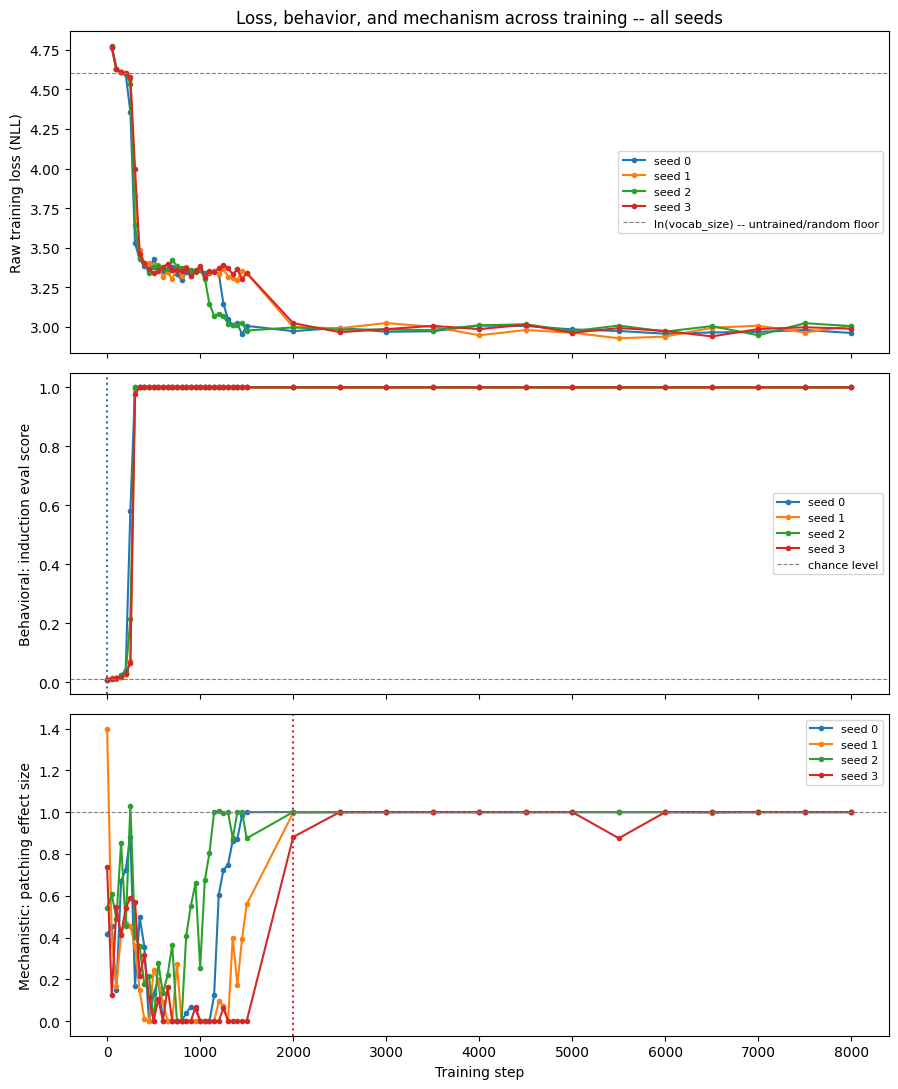

Saved figure to /content/drive/MyDrive/sentinelbench_gpt2_results/behavior_vs_mechanism_57c45749eb6d.png


In [ ]:
fig, axes = plt.subplots(3, 1, figsize=(9, 11), sharex=True)

for seed in CONFIG.seeds:
    sub = merged[merged.seed == seed].sort_values("step")
    axes[0].plot(sub.step, sub.raw_loss, marker="o", ms=3, label=f"seed {seed}")
    axes[1].plot(sub.step, sub.induction_eval_score, marker="o", ms=3, label=f"seed {seed}")
    axes[2].plot(sub.step, sub.patch_effect_size, marker="o", ms=3, label=f"seed {seed}")

import math as _math
axes[0].axhline(_math.log(CONFIG.vocab_size), color="gray", ls="--", lw=0.8,
                label="ln(vocab_size) -- untrained/random floor")
axes[0].set_ylabel("Raw training loss (NLL)")
axes[0].legend(fontsize=8)
axes[0].set_title("Loss, behavior, and mechanism across training -- all seeds")

axes[1].set_ylabel("Behavioral: induction eval score")
axes[1].axhline(1.0 / CONFIG.vocab_size, color="gray", ls="--", lw=0.8, label="chance level")
axes[1].legend(fontsize=8)

axes[2].set_ylabel("Mechanistic: patching effect size")
axes[2].set_xlabel("Training step")
axes[2].axhline(1.0, color="gray", ls="--", lw=0.8)
axes[2].legend(fontsize=8)

if T_b is not None:
    axes[1].axvline(T_b, color="tab:blue", ls=":", lw=1.5)
if T_m is not None:
    axes[2].axvline(T_m, color="tab:red", ls=":", lw=1.5)

plt.tight_layout()
fig_path = os.path.join(RESULTS_DIR, f"behavior_vs_mechanism_{CONFIG.config_hash()}.png")
plt.savefig(fig_path, dpi=150)
plt.show()
print("Saved figure to", fig_path)


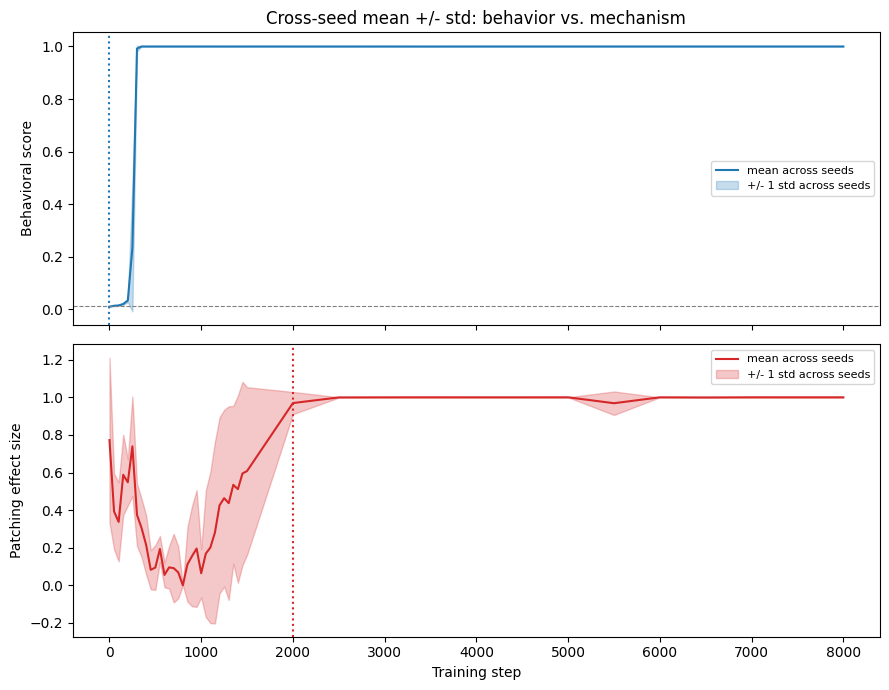

Saved figure to /content/drive/MyDrive/sentinelbench_gpt2_results/variance_bands_57c45749eb6d.png


In [ ]:
# --- Cross-seed variance bands: mean +/- std, rather than just the raw per-seed lines ---
fig, axes = plt.subplots(2, 1, figsize=(9, 7), sharex=True)

vb = variance_by_step
axes[0].plot(vb.step, vb.behavior_mean, color="tab:blue", label="mean across seeds")
axes[0].fill_between(vb.step, vb.behavior_mean - vb.behavior_std.fillna(0),
                      vb.behavior_mean + vb.behavior_std.fillna(0), alpha=0.25, color="tab:blue",
                      label="+/- 1 std across seeds")
axes[0].axhline(1.0 / CONFIG.vocab_size, color="gray", ls="--", lw=0.8)
axes[0].set_ylabel("Behavioral score")
axes[0].set_title("Cross-seed mean +/- std: behavior vs. mechanism")
axes[0].legend(fontsize=8)
if T_b is not None:
    axes[0].axvline(T_b, color="tab:blue", ls=":", lw=1.5)

axes[1].plot(vb.step, vb.mech_mean, color="tab:red", label="mean across seeds")
axes[1].fill_between(vb.step, vb.mech_mean - vb.mech_std.fillna(0),
                      vb.mech_mean + vb.mech_std.fillna(0), alpha=0.25, color="tab:red",
                      label="+/- 1 std across seeds")
axes[1].set_ylabel("Patching effect size")
axes[1].set_xlabel("Training step")
axes[1].legend(fontsize=8)
if T_m is not None:
    axes[1].axvline(T_m, color="tab:red", ls=":", lw=1.5)

plt.tight_layout()
fig_path2 = os.path.join(RESULTS_DIR, f"variance_bands_{CONFIG.config_hash()}.png")
plt.savefig(fig_path2, dpi=150)
plt.show()
print("Saved figure to", fig_path2)


Resuming: found 4 seed(s) already done: [np.int64(0), np.int64(1), np.int64(2), np.int64(3)]
Seed 0 already done -- skipping
Seed 1 already done -- skipping
Seed 2 already done -- skipping
Seed 3 already done -- skipping


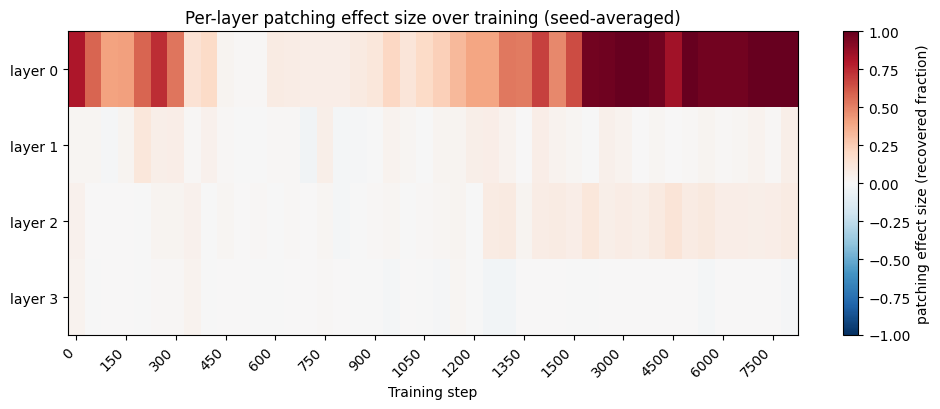

Saved figure to /content/drive/MyDrive/sentinelbench_gpt2_results/per_layer_heatmap_57c45749eb6d.png


In [ ]:
# --- Per-layer patching heatmap over training (seed-averaged) ---
# Re-run activation patching but keep the full per-layer vector rather than just the argmax,
# so we can see *which* layer picks up the induction circuit and when -- not just whether one did.

PER_LAYER_CSV_PATH = os.path.join(RESULTS_DIR, f"per_layer_patching_{CONFIG.config_hash()}.csv")

if os.path.exists(PER_LAYER_CSV_PATH):
    per_layer_df_existing = pd.read_csv(PER_LAYER_CSV_PATH)
    completed_seeds_pl = set(per_layer_df_existing["seed"].unique())
    per_layer_records = per_layer_df_existing.to_dict("records")
    print(f"Resuming: found {len(completed_seeds_pl)} seed(s) already done: "
          f"{sorted(completed_seeds_pl)}")
else:
    per_layer_records = []
    completed_seeds_pl = set()

for seed in CONFIG.seeds:
    if seed in completed_seeds_pl:
        print(f"Seed {seed} already done -- skipping")
        continue
    print(f"Per-layer patching, seed {seed}...")
    rng = random.PRNGKey(seed + 20_000)
    seed_records = []
    for step, params in all_saved_params[seed].items():
        rng, patch_rng = random.split(rng)
        layer_effects = activation_patching_effect(model_ref, params, CONFIG, patch_rng, n_pairs=8)
        for layer_idx, effect in enumerate(layer_effects):
            seed_records.append({
                "seed": seed, "step": step, "layer": layer_idx, "effect": float(effect)
            })
    per_layer_records.extend(seed_records)
    pd.DataFrame(per_layer_records).to_csv(PER_LAYER_CSV_PATH, index=False)
    print(f"  Checkpointed seed {seed} to {PER_LAYER_CSV_PATH}")

per_layer_df = pd.DataFrame(per_layer_records)

heatmap_data = per_layer_df.groupby(["layer", "step"])["effect"].mean().unstack("step")

fig, ax = plt.subplots(figsize=(10, 3 + 0.3 * CONFIG.n_layers))
im = ax.imshow(heatmap_data.values, aspect="auto", cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_yticks(range(len(heatmap_data.index)))
ax.set_yticklabels([f"layer {i}" for i in heatmap_data.index])
step_ticks = list(range(0, len(heatmap_data.columns), max(1, len(heatmap_data.columns) // 12)))
ax.set_xticks(step_ticks)
ax.set_xticklabels([str(heatmap_data.columns[i]) for i in step_ticks], rotation=45, ha="right")
ax.set_xlabel("Training step")
ax.set_title("Per-layer patching effect size over training (seed-averaged)")
fig.colorbar(im, ax=ax, label="patching effect size (recovered fraction)")
plt.tight_layout()
fig_path3 = os.path.join(RESULTS_DIR, f"per_layer_heatmap_{CONFIG.config_hash()}.png")
plt.savefig(fig_path3, dpi=150)
plt.show()
print("Saved figure to", fig_path3)


In [ ]:
# --- Logit lens: is the correct answer represented earlier in the layers than it's used? ---
# Take the trained model at the final checkpoint of each seed and show how the log-prob of the
# correct induction target builds up layer by layer -- a rising curve before the final layer
# suggests the answer is represented internally before the model "commits" to it at the output.

fig, ax = plt.subplots(figsize=(8, 5))
for seed in CONFIG.seeds:
    final_step = max(all_saved_params[seed].keys())
    final_params = all_saved_params[seed][final_step]
    rng = random.PRNGKey(seed + 30_000)
    clean, _, target_pos, target_tok = make_clean_corrupt_pair(CONFIG, rng)
    traj = logit_lens_trajectory(model_ref, final_params, clean, target_pos, target_tok, CONFIG)
    ax.plot(range(CONFIG.n_layers), traj, marker="o", label=f"seed {seed} (step {final_step})")

ax.set_xlabel("Layer (post-block residual stream)")
ax.set_ylabel("Log-prob of correct induction target")
ax.set_title("Logit lens: where does the correct answer become represented?")
ax.legend(fontsize=8)
plt.tight_layout()
fig_path4 = os.path.join(RESULTS_DIR, f"logit_lens_{CONFIG.config_hash()}.png")
plt.savefig(fig_path4, dpi=150)
plt.show()
print("Saved figure to", fig_path4)


<p align="left">
  <img src="../figures/behavior_vs_mechanism.png" width="850">
</p>

## 7b. Bootstrap confidence interval on T_b vs. T_m

`first_stable_step` with fixed thresholds is a reasonable pre-specified rule, but it's a single
number computed from a single set of seeds -- it doesn't tell us how sensitive the T_b < T_m /
T_m < T_b conclusion is to which seeds happened to be sampled. We resample seeds with replacement
(the standard seed-level bootstrap), recompute T_b and T_m on each resample, and report what
fraction of resamples agree on the *direction* of the gap. If, say, 95% of bootstrap resamples show
T_b < T_m, that's a much stronger claim than a single point estimate with no uncertainty attached.


In [ ]:
def bootstrap_stability_gap(records_df, seeds, n_boot=300, rng_seed=0):
    rng_np = np.random.default_rng(rng_seed)
    gaps, tb_list, tm_list = [], [], []
    for _ in range(n_boot):
        resampled_seeds = rng_np.choice(seeds, size=len(seeds), replace=True)
        sub = pd.concat([records_df[records_df.seed == s] for s in resampled_seeds], ignore_index=True)
        vb = sub.groupby("step").agg(
            behavior_std=("induction_eval_score", "std"),
            mech_std=("patch_effect_size", "std"),
        ).reset_index()
        steps_ = vb["step"].tolist()
        tb = first_stable_step(steps_, vb["behavior_std"].fillna(1.0).tolist(), BEHAVIOR_STABILITY_THRESHOLD)
        tm = first_stable_step(steps_, vb["mech_std"].fillna(1.0).tolist(), MECH_STABILITY_THRESHOLD)
        tb_list.append(tb)
        tm_list.append(tm)
        if tb is not None and tm is not None:
            gaps.append(tb - tm)
    return np.array(gaps), tb_list, tm_list


gaps, tb_boot, tm_boot = bootstrap_stability_gap(merged, list(CONFIG.seeds), n_boot=300)

if len(gaps) > 0:
    frac_behavior_first = float((gaps < 0).mean())
    frac_mech_first = float((gaps > 0).mean())
    frac_tie = float((gaps == 0).mean())
    print(f"Bootstrap resamples with a usable T_b and T_m: {len(gaps)} / 300")
    print(f"  P(T_b < T_m)  [behavior stabilizes first]:   {frac_behavior_first:.2f}")
    print(f"  P(T_m < T_b)  [mechanism stabilizes first]:  {frac_mech_first:.2f}")
    print(f"  P(T_b == T_m):                                {frac_tie:.2f}")
    print(f"  Median gap (T_b - T_m): {np.median(gaps):.1f} steps  "
          f"[90% CI: {np.percentile(gaps, 5):.1f}, {np.percentile(gaps, 95):.1f}]")
    print("\nInterpretation: if one of the two probabilities above is close to 1.0, the direction "
          "of the effect is robust to which seeds you happened to run. If it's closer to 0.5, the "
          "point-estimate T_b/T_m comparison from Section 7 is not reliable on its own -- more "
          "seeds are needed before drawing a directional conclusion.")
else:
    print("No bootstrap resample produced both a usable T_b and T_m -- likely because too few "
          "seeds/checkpoints exist to compute stability under the given thresholds. Increase "
          "`seeds` or loosen the thresholds and rerun Sections 6-7 before trusting Section 7's "
          "point estimate.")


Bootstrap resamples with a usable T_b and T_m: 300 / 300
  P(T_b < T_m)  [behavior stabilizes first]:   0.98
  P(T_m < T_b)  [mechanism stabilizes first]:  0.00
  P(T_b == T_m):                                0.02
  Median gap (T_b - T_m): -550.0 steps  [90% CI: -2000.0, -150.0]

Interpretation: if one of the two probabilities above is close to 1.0, the direction of the effect is robust to which seeds you happened to run. If it's closer to 0.5, the point-estimate T_b/T_m comparison from Section 7 is not reliable on its own -- more seeds are needed before drawing a directional conclusion.


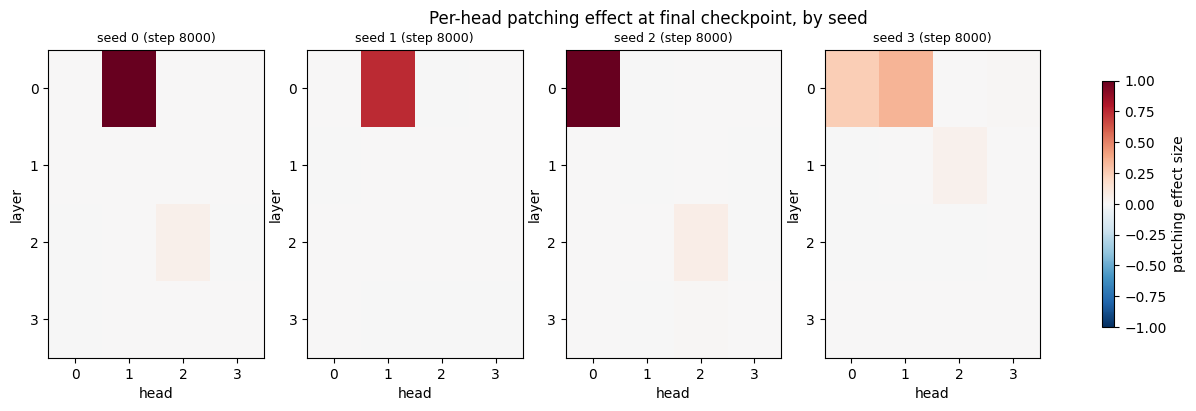

Saved figure to /content/drive/MyDrive/sentinelbench_gpt2_results/per_head_final_57c45749eb6d.png

If effects concentrate in one (layer, head) cell consistently across seeds, that's a strong, specific mechanistic claim ('head L.H is the induction head'). If effects are diffuse across many heads/layers, or inconsistent across seeds, the circuit is either distributed or not cleanly localized at this model scale -- also a real, reportable finding.


In [ ]:
# --- Per-head patching heatmap at each seed's final checkpoint ---
# Cheaper than running per-head patching at every checkpoint: this answers "does the effect
# localize to a specific head by the end of training", the main question per-head patching adds
# beyond the layer-level heatmap already computed in Section 7.

fig, axes = plt.subplots(1, len(CONFIG.seeds), figsize=(4 * len(CONFIG.seeds), 4), squeeze=False)
axes = axes[0]

for ax, seed in zip(axes, CONFIG.seeds):
    final_step = max(all_saved_params[seed].keys())
    final_params = all_saved_params[seed][final_step]
    rng = random.PRNGKey(seed + 40_000)
    head_effects = activation_patching_effect_per_head(model_ref, final_params, CONFIG, rng, n_pairs=4)

    im = ax.imshow(head_effects, cmap="RdBu_r", vmin=-1, vmax=1, aspect="auto")
    ax.set_title(f"seed {seed} (step {final_step})", fontsize=9)
    ax.set_xlabel("head")
    ax.set_ylabel("layer")
    ax.set_xticks(range(CONFIG.n_heads))
    ax.set_yticks(range(CONFIG.n_layers))

fig.suptitle("Per-head patching effect at final checkpoint, by seed")
fig.colorbar(im, ax=axes.tolist(), label="patching effect size", shrink=0.8)
fig_path5 = os.path.join(RESULTS_DIR, f"per_head_final_{CONFIG.config_hash()}.png")
plt.savefig(fig_path5, dpi=150)
plt.show()
print("Saved figure to", fig_path5)
print("\nIf effects concentrate in one (layer, head) cell consistently across seeds, that's a "
      "strong, specific mechanistic claim ('head L.H is the induction head'). If effects are "
      "diffuse across many heads/layers, or inconsistent across seeds, the circuit is either "
      "distributed or not cleanly localized at this model scale -- also a real, reportable finding.")


## 7c. Negative control: does the pipeline detect an effect where none should exist?

Everything above assumes that a nonzero patching effect or an above-chance behavioural score means
"the model learned induction." Before trusting that, we need to rule out the alternative
explanation: **that these numbers are just artifacts of training in general** (e.g. any trained
model's activations differ somewhat between two different sequences, regardless of task).

This negative control trains models on data with **`frac_induction_sequences = 0`** — every
sequence is fully unstructured, no repeated-chunk pattern ever appears in training. We then run the
*exact same* induction-behaviour eval and the *exact same* clean/corrupt patching probe used
everywhere else. If the pipeline is measuring something real and specific to learned induction, both
signals should stay flat and near their chance/noise floor throughout training here -- since the
model has no way to learn a behaviour it never saw. If they *don't* stay flat, that's evidence the
main-experiment numbers may be measurement artifacts rather than a genuine learned circuit, and the
main result should not be trusted without further investigation.


Negative control config_hash: 584a4b4b2a1c

=== [negative control] Training seed 0 ===
[seed 0] step     0  induction_eval_score=0.000  weighted_loss=n/a  raw_loss=n/a
[seed 0] step  1000  induction_eval_score=0.000  weighted_loss=4.608  raw_loss=4.607
[seed 0] step  2000  induction_eval_score=0.000  weighted_loss=4.607  raw_loss=4.606
[seed 0] step  3000  induction_eval_score=0.000  weighted_loss=4.607  raw_loss=4.606
[seed 0] step  4000  induction_eval_score=0.000  weighted_loss=4.606  raw_loss=4.606
[seed 0] step  5000  induction_eval_score=0.000  weighted_loss=4.606  raw_loss=4.605
[seed 0] step  6000  induction_eval_score=0.000  weighted_loss=4.606  raw_loss=4.605
[seed 0] step  7000  induction_eval_score=0.000  weighted_loss=4.605  raw_loss=4.605
[seed 0] step  8000  induction_eval_score=0.000  weighted_loss=4.605  raw_loss=4.605

=== [negative control] Training seed 1 ===
[seed 1] step     0  induction_eval_score=0.000  weighted_loss=n/a  raw_loss=n/a
[seed 1] step  1000  induct

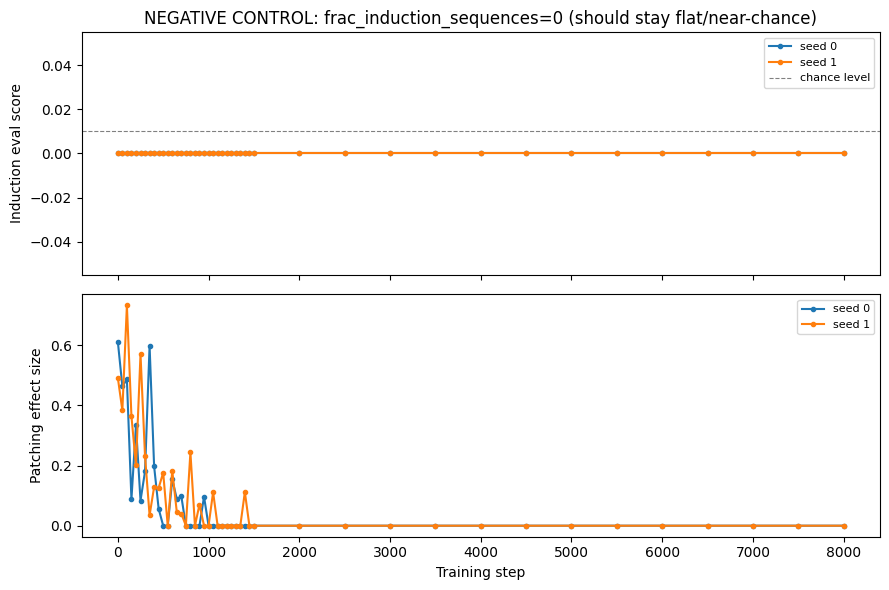


Negative control max behavioral score observed: 0.000 (chance = 0.010)
Negative control max patching effect, ALL steps (including step 0): 0.732
Negative control max patching effect, EXCLUDING step 0: 0.732
Negative control patching effect at final step (8000): 0.000

Step 0 is an untrained, randomly-initialized model -- we already know from Sections 5-7 that the clean/corrupted logit gap can be numerically unstable pre-training, producing spuriously large patching values that reflect init noise, not a learned circuit. If `max_neg_patch_all` is much larger than `max_neg_patch_excl_step0` or the final-step value, that confirms the step-0 number is this known artifact and should be excluded from the comparison below -- compare the main experiment's values at comparable (post-training) checkpoints against `max_neg_patch_excl_step0`, not against the raw all-steps maximum.

Compare the main experiment's post-training peak values against the excl-step-0 ceiling above. If the main experiment

In [ ]:
import dataclasses

NEGATIVE_CONTROL_CONFIG = dataclasses.replace(
    CONFIG,
    frac_induction_sequences=0.0,   # <-- the only thing that changes: no induction structure ever
    seeds=CONFIG.seeds[:2],          # cheaper: 2 seeds is enough to sanity-check "stays flat"
)

print("Negative control config_hash:", NEGATIVE_CONTROL_CONFIG.config_hash())

neg_records = []
neg_saved_params = {}
neg_model_ref = None
for seed in NEGATIVE_CONTROL_CONFIG.seeds:
    print(f"\n=== [negative control] Training seed {seed} ===")
    model, records, saved_params = run_training(NEGATIVE_CONTROL_CONFIG, seed, verbose_every=1000)
    neg_records.extend(records)
    neg_saved_params[seed] = saved_params
    neg_model_ref = model

neg_behavior_df = pd.DataFrame(neg_records)

neg_mech_records = []
for seed in NEGATIVE_CONTROL_CONFIG.seeds:
    rng = random.PRNGKey(seed + 50_000)
    for step, params in neg_saved_params[seed].items():
        rng, patch_rng = random.split(rng)
        layer_effects = activation_patching_effect(neg_model_ref, params, NEGATIVE_CONTROL_CONFIG,
                                                      patch_rng, n_pairs=8)
        neg_mech_records.append({
            "seed": seed, "step": step, "patch_effect_size": float(np.max(layer_effects)),
        })

neg_mech_df = pd.DataFrame(neg_mech_records)
neg_merged = neg_behavior_df.merge(neg_mech_df, on=["seed", "step"])
neg_merged.to_csv(os.path.join(RESULTS_DIR, f"negative_control_{NEGATIVE_CONTROL_CONFIG.config_hash()}.csv"),
                   index=False)

fig, axes = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
for seed in NEGATIVE_CONTROL_CONFIG.seeds:
    sub = neg_merged[neg_merged.seed == seed].sort_values("step")
    axes[0].plot(sub.step, sub.induction_eval_score, marker="o", ms=3, label=f"seed {seed}")
    axes[1].plot(sub.step, sub.patch_effect_size, marker="o", ms=3, label=f"seed {seed}")
axes[0].axhline(1.0 / CONFIG.vocab_size, color="gray", ls="--", lw=0.8, label="chance level")
axes[0].set_ylabel("Induction eval score")
axes[0].set_title("NEGATIVE CONTROL: frac_induction_sequences=0 (should stay flat/near-chance)")
axes[0].legend(fontsize=8)
axes[1].set_ylabel("Patching effect size")
axes[1].set_xlabel("Training step")
axes[1].legend(fontsize=8)
plt.tight_layout()
neg_fig_path = os.path.join(RESULTS_DIR, f"negative_control_{NEGATIVE_CONTROL_CONFIG.config_hash()}.png")
plt.savefig(neg_fig_path, dpi=150)
plt.show()

max_neg_behavior = neg_merged["induction_eval_score"].max()
max_neg_patch_all = neg_merged["patch_effect_size"].max()
max_neg_patch_excl_step0 = neg_merged[neg_merged.step > 0]["patch_effect_size"].max()
final_neg_step = neg_merged["step"].max()
final_neg_patch = neg_merged[neg_merged.step == final_neg_step]["patch_effect_size"].max()

print(f"\nNegative control max behavioral score observed: {max_neg_behavior:.3f} "
      f"(chance = {1.0/CONFIG.vocab_size:.3f})")
print(f"Negative control max patching effect, ALL steps (including step 0): {max_neg_patch_all:.3f}")
print(f"Negative control max patching effect, EXCLUDING step 0: {max_neg_patch_excl_step0:.3f}")
print(f"Negative control patching effect at final step ({final_neg_step}): {final_neg_patch:.3f}")
print("\nStep 0 is an untrained, randomly-initialized model -- we already know from Sections 5-7 "
      "that the clean/corrupted logit gap can be numerically unstable pre-training, producing "
      "spuriously large patching values that reflect init noise, not a learned circuit. If "
      "`max_neg_patch_all` is much larger than `max_neg_patch_excl_step0` or the final-step value, "
      "that confirms the step-0 number is this known artifact and should be excluded from the "
      "comparison below -- compare the main experiment's values at comparable (post-training) "
      "checkpoints against `max_neg_patch_excl_step0`, not against the raw all-steps maximum.")
print("\nCompare the main experiment's post-training peak values against the excl-step-0 ceiling "
      "above. If the main experiment's values are clearly and consistently higher, that supports "
      "treating the main result as a genuine learned effect. If they're similar in magnitude, the "
      "patching methodology itself may not be specific enough at this model scale to distinguish "
      "learned induction from noise, and the main result should be treated cautiously until the "
      "measurement is made more robust (e.g. more patching pairs, per-head localization from "
      "Section 5b, or a larger model).")


## 7d. Robustness scan across model scale (quick, low-cost)

A finding that only holds at one specific `d_model` is a much weaker claim than one that holds
across scales. This is a **cheap scan**, not the main experiment: fewer steps, fewer seeds, just
enough to see whether the qualitative pattern (does induction emerge at all? does a patching
effect appear?) is consistent as model size changes. If you see the same qualitative story at
multiple scales, that's a real robustness claim worth reporting; if it flips, that's also
important to know before generalizing the main result.


In [ ]:
SCALE_SCAN_STEPS = 4000          # cheaper than the main experiment's total_steps
SCALE_SCAN_SEEDS = CONFIG.seeds[:2]
SCALE_PRESETS = [
    {"d_model": 64, "n_layers": 2, "n_heads": 2, "d_ff": 256},
    {"d_model": 128, "n_layers": 4, "n_heads": 4, "d_ff": 512},   # same as main default
    {"d_model": 256, "n_layers": 4, "n_heads": 8, "d_ff": 1024},
]

scale_scan_rows = []
for preset in SCALE_PRESETS:
    scan_cfg = dataclasses.replace(
        CONFIG,
        seeds=SCALE_SCAN_SEEDS,
        total_steps=SCALE_SCAN_STEPS,
        dense_ckpt_until=SCALE_SCAN_STEPS,
        dense_ckpt_every=max(SCALE_SCAN_STEPS // 15, 50),
        sparse_ckpt_every=SCALE_SCAN_STEPS,
        **preset,
    )
    print(f"\n=== Scale scan: d_model={preset['d_model']}, n_layers={preset['n_layers']} ===")
    for seed in scan_cfg.seeds:
        model, records, saved_params = run_training(scan_cfg, seed, verbose_every=SCALE_SCAN_STEPS)
        final_step = max(saved_params.keys())
        final_params = saved_params[final_step]
        rng = random.PRNGKey(seed + 60_000)
        layer_effects = activation_patching_effect(model, final_params, scan_cfg, rng, n_pairs=6)
        final_behavior = records[-1]["induction_eval_score"]
        scale_scan_rows.append({
            "d_model": preset["d_model"],
            "n_layers": preset["n_layers"],
            "seed": seed,
            "final_induction_eval_score": final_behavior,
            "final_patch_effect_size": float(np.max(layer_effects)),
        })

scale_scan_df = pd.DataFrame(scale_scan_rows)
scale_scan_df.to_csv(os.path.join(RESULTS_DIR, "scale_scan.csv"), index=False)
scale_scan_summary = scale_scan_df.groupby(["d_model", "n_layers"]).agg(
    mean_behavior=("final_induction_eval_score", "mean"),
    mean_patch_effect=("final_patch_effect_size", "mean"),
).reset_index()
print("\nScale scan summary (mean across seeds, after", SCALE_SCAN_STEPS, "steps):")
scale_scan_summary



=== Scale scan: d_model=64, n_layers=2 ===
[seed 0] step     0  induction_eval_score=0.009  weighted_loss=n/a  raw_loss=n/a
[seed 0] step  4000  induction_eval_score=1.000  weighted_loss=1.991  raw_loss=3.313
[seed 1] step     0  induction_eval_score=0.011  weighted_loss=n/a  raw_loss=n/a
[seed 1] step  4000  induction_eval_score=1.000  weighted_loss=2.019  raw_loss=3.341

=== Scale scan: d_model=128, n_layers=4 ===
[seed 0] step     0  induction_eval_score=0.009  weighted_loss=n/a  raw_loss=n/a
[seed 0] step  4000  induction_eval_score=1.000  weighted_loss=1.730  raw_loss=2.963
[seed 1] step     0  induction_eval_score=0.010  weighted_loss=n/a  raw_loss=n/a
[seed 1] step  4000  induction_eval_score=1.000  weighted_loss=1.762  raw_loss=2.996

=== Scale scan: d_model=256, n_layers=4 ===
[seed 0] step     0  induction_eval_score=0.011  weighted_loss=n/a  raw_loss=n/a
[seed 0] step  4000  induction_eval_score=1.000  weighted_loss=1.730  raw_loss=2.963
[seed 1] step     0  induction_eval_

,d_model,n_layers,mean_behavior,mean_patch_effect
0,64,2,1.0,0.088118
1,128,4,1.0,0.999526
2,256,4,1.0,1.000020


## 8. Scaling this up (spending real compute budget)

The default config above is a **pipeline-validation run** — small enough to finish on a free CPU
runtime. Once you've confirmed the whole pipeline runs end to end and the plots consistent with the expected behaviour scale up
along these axes (each roughly independent, so change one at a time and re-check the pipeline still
behaves sensibly):

| Axis | Default | Scaled-up suggestion | Effect |
|---|---|---|---|
| `d_model` / `n_layers` / `n_heads` | 128 / 4 / 4 | 256 / 8 / 8 (closer to GPT-2-small proportions) | Needs a T4/A100 runtime; induction heads are known to require ≥2 layers, so don't go below that |
| `total_steps` | 3000 | 10,000–20,000 | Longer runs needed to see emergence clearly at larger model size |
| `seeds` | 4 | 8–10 | More seeds = more reliable cross-seed variance estimate, the actual quantity the hypothesis depends on |
| `vocab_size` / real data | synthetic, 512 | swap in a real tokenized corpus subset (e.g. a WikiText slice) with the induction-probe construction overlaid | Tests whether the effect holds outside the fully synthetic setting |
| `activation_patching_effect` | position-targeted, single attention output per layer | full per-head patching (patch individual attention heads, not whole layers) | Localizes to the specific induction head(s), not just the layer — closer to the standard methodology |

**Recommended order:** (1) confirm the default run produces a sensible T_b/T_m split, (2) increase
seeds to 8 before anything else since cross-seed variance is the actual quantity under study, (3)
then scale model size and step count together, (4) only move to real text data once the synthetic
result is solid and you want to test generalization.



## 9. What to report

Whatever T_b / T_m relationship you find is a real result! This design was built so that all three
outcomes (behaviour leads, mechanism leads, or they coincide) provide meaningful evidence about how behavioural and mechanistic measurements relate during training.

- **T_b < T_m** (behaviour looks stable first): the eval score gives false confidence that a
  capability is "learned" before the circuit implementing it is reliable across random seeds —
  directly relevant to any evaluation practice that treats a stabilized eval curve as evidence a
  capability is robustly present.
- **T_m < T_b** (mechanism stabilizes first): the circuit exists earlier than behavioural scores
  reliably reflect it — suggests eval scores are conservative/noisy indicators rather than
  leading indicators, a different but also useful finding for anyone relying on evals as an
  early-warning signal.
- **T_b ≈ T_m**: no detectable gap at this scale/threshold — worth reporting as a boundary
  condition (e.g. "at this model scale and task, behavioural and mechanistic stability coincide;
  open question whether this holds at larger scale").



## 10. Why this matters beyond this toy setting

This notebook asks whether behavioural and mechanistic measurements of the same capability stabilize at the same point during training. If they evolve on different timelines, stable behavioural performance alone does not establish that the underlying mechanism or our measurement of it has also stabilized. The controls and robustness analyses test whether this separation persists beyond transient noise or a single experimental configuration. More broadly, the results suggest that behavioural performance alone may not provide a complete picture of how a learned capability develops during training.


## 11. Real-text replication: Pride and Prejudice

Everything above uses a fully synthetic task with random tokens and no real language, so the correct answer is unambiguous and inexpensive to score. This section adds a second, complementary track, replicating three diagnostic visualizations from Anthropic's original induction-heads work using Jane Austen's Pride and Prejudice (Project Gutenberg, first published 1813) in place of the copyrighted text used in some public versions of those figures. Pride and Prejudice is in the public domain, allowing the experiment and its associated text to be freely shared and reproduced.

This section is a **second experimental track**, not a replacement for Sections 1–10: it trains
new, real-text models (real English, real tokenizer) from scratch, separate from the synthetic
induction-task models above, because the synthetic models' 100-token abstract vocabulary has no
meaningful mapping onto English words.

Three additions, in order:

1. **A schematic diagram** of the induction mechanism itself (no training required) — attend back
   to an earlier occurrence of the current token, copy whatever followed it.
2. **A small depth-scaling replication** (1-layer, 2-layer, 3-layer attention-only models, trained
   on real text) reproducing the "does loss keep improving with longer context, post phase-change"
   heatmap from the original work.
3. **A real-text qualitative example**: color-coded per-token prediction quality on an actual
   *Pride and Prejudice* passage, before vs. after a model's phase change, showing concretely what
   "the circuit forming" does to real predictions — not just to a synthetic accuracy number.


### 11.1 Schematic: what the induction mechanism actually does

This is a pure explanatory figure — no training, no data. It illustrates the general mechanism
that both the synthetic task (Sections 1–10) and the real-text replication (11.2 onward) are
trying to detect: given a repeated span, attend back to the earlier occurrence of the *current*
token, and copy whatever token followed it there.


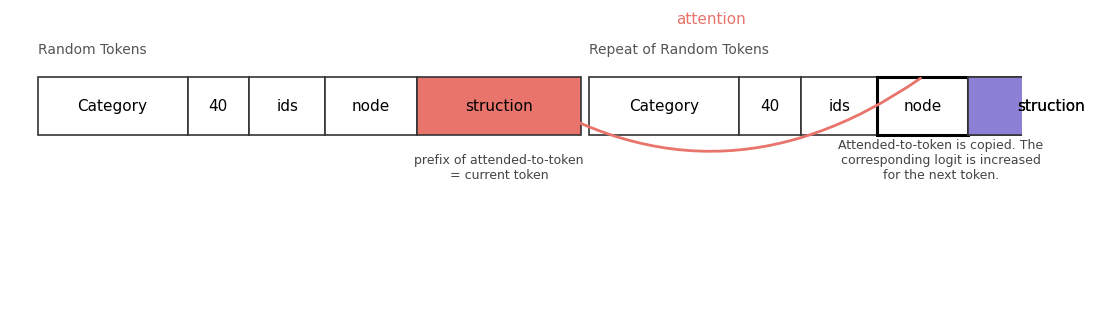

Saved /content/drive/MyDrive/sentinelbench_gpt2_results/induction_schematic.png


In [ ]:
import matplotlib.patches as mpatches
from matplotlib.patches import FancyArrowPatch

fig, ax = plt.subplots(figsize=(11, 3.2))
ax.set_xlim(0, 11)
ax.set_ylim(0, 3)
ax.axis("off")

first_tokens = ["Category", "40", "ids", "node", "struction"]
second_tokens = ["Category", "40", "ids", "node", "struction"]

def draw_tokens(tokens, x0, y, highlight_idx=None, highlight_color="#e8746b",
                box_edge=None, box_idx=None):
    x = x0
    widths = []
    for i, tok in enumerate(tokens):
        w = 0.35 + 0.16 * len(tok)
        widths.append(w)
        face = highlight_color if i == highlight_idx else "white"
        ax.add_patch(plt.Rectangle((x, y), w, 0.6, facecolor=face,
                                    edgecolor="#333333", linewidth=1.2))
        if box_idx is not None and i == box_idx:
            ax.add_patch(plt.Rectangle((x, y), w, 0.6, facecolor="none",
                                        edgecolor="black", linewidth=2.2))
        ax.text(x + w / 2, y + 0.3, tok, ha="center", va="center", fontsize=11)
        x += w
    return x, widths

ax.text(0.3, 2.55, "Random Tokens", fontsize=10, color="#555555")
end1, widths1 = draw_tokens(first_tokens, 0.3, 1.7, highlight_idx=4)

ax.text(6.3, 2.55, "Repeat of Random Tokens", fontsize=10, color="#555555")
end2, widths2 = draw_tokens(second_tokens, 6.3, 1.7, highlight_idx=None, box_idx=3)
# manually recolor the last box purple to match "copied" token
last_x = 6.3 + sum(widths2[:-1])
ax.add_patch(plt.Rectangle((last_x, 1.7), widths2[-1], 0.6, facecolor="#8b7fd6",
                            edgecolor="#333333", linewidth=1.2))
ax.text(last_x + widths2[-1] / 2, 1.7 + 0.3, second_tokens[-1], ha="center", va="center", fontsize=11)

# attention arrow
node_x = 6.3 + sum(widths2[:3]) + widths2[3] / 2
struction1_x = 0.3 + sum(widths1[:4]) + widths1[4] / 2
arrow = FancyArrowPatch((node_x, 2.3), (struction1_x, 2.3), connectionstyle="arc3,rad=-0.35",
                         arrowstyle="-|>", mutation_scale=20, color="#e8746b", linewidth=2)
ax.add_patch(arrow)
ax.text((node_x + struction1_x) / 2, 2.85, "attention", color="#e8746b", fontsize=11, ha="center")

ax.text(struction1_x, 1.25, "prefix of attended-to-token\n= current token", ha="center",
        fontsize=9, color="#444444")
ax.text(last_x - 0.3, 1.25, "Attended-to-token is copied. The\ncorresponding logit is increased\nfor the next token.",
        ha="center", fontsize=9, color="#444444")

plt.tight_layout()
schematic_path = os.path.join(RESULTS_DIR, "induction_schematic.png")
plt.savefig(schematic_path, dpi=150, bbox_inches="tight")
plt.show()
print("Saved", schematic_path)


### 11.2 Data: downloading *Pride and Prejudice* (public domain)

Fetched directly from Project Gutenberg at runtime — nothing is hardcoded or bundled, so this
always pulls the current canonical edition. We strip Project Gutenberg's standard header/footer
boilerplate (the `*** START OF ... ***` / `*** END OF ... ***` markers) and keep only the novel's
text.


In [ ]:
import re
import urllib.request

GUTENBERG_URL = "https://www.gutenberg.org/files/1342/1342-0.txt"

def fetch_pride_and_prejudice(url: str = GUTENBERG_URL) -> str:
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req, timeout=30) as resp:
        raw = resp.read().decode("utf-8-sig", errors="replace")

    start_match = re.search(r"\*\*\* START OF (THE|THIS) PROJECT GUTENBERG EBOOK.*?\*\*\*", raw)
    end_match = re.search(r"\*\*\* END OF (THE|THIS) PROJECT GUTENBERG EBOOK.*?\*\*\*", raw)
    start = start_match.end() if start_match else 0
    end = end_match.start() if end_match else len(raw)
    text = raw[start:end].strip()
    return text


# For a local/offline fallback (e.g. no internet access this session), set this to a local path
# containing any plain-text excerpt; otherwise leave as None to fetch fresh from Gutenberg.
LOCAL_FALLBACK_PATH = None

if LOCAL_FALLBACK_PATH and os.path.exists(LOCAL_FALLBACK_PATH):
    pnp_text = open(LOCAL_FALLBACK_PATH, encoding="utf-8").read()
else:
    pnp_text = fetch_pride_and_prejudice()

print(f"Loaded {len(pnp_text):,} characters.")
print(pnp_text[:300])


Loaded 728,713 characters.
[Illustration:

                             GEORGE ALLEN
                               PUBLISHER

                        156 CHARING CROSS ROAD
                                LONDON

                             RUSKIN HOUSE
                                   ]

                            [Illu


In [ ]:
# --- Character-level tokenizer ---
# A character-level vocabulary is the simplest choice that requires no external tokenizer
# library, keeps the vocabulary small (fits comfortably in a tiny model), and needs no
# subword-merge training step -- appropriate for a small-scale replication at this model size.

chars = sorted(set(pnp_text))
PNP_VOCAB_SIZE = len(chars)
char_to_id = {c: i for i, c in enumerate(chars)}
id_to_char = {i: c for i, c in enumerate(chars)}

def encode_text(s: str):
    return np.array([char_to_id[c] for c in s if c in char_to_id], dtype=np.int32)

def decode_ids(ids):
    return "".join(id_to_char[int(i)] for i in ids)

pnp_ids = encode_text(pnp_text)
print(f"Vocab size: {PNP_VOCAB_SIZE}")
print(f"Total tokens (characters): {len(pnp_ids):,}")

# Held out a contiguous final slice as an evaluation region, so the qualitative example in
# Section 11.5 can optionally be checked against text the depth-scaling models were not
# directly trained to memorize the tail of.
PNP_SPLIT = int(len(pnp_ids) * 0.95)
pnp_train_ids, pnp_eval_ids = pnp_ids[:PNP_SPLIT], pnp_ids[PNP_SPLIT:]
print(f"Train tokens: {len(pnp_train_ids):,}   Eval-region tokens: {len(pnp_eval_ids):,}")


Vocab size: 91
Total tokens (characters): 728,713
Train tokens: 692,277   Eval-region tokens: 36,436


### 11.3 Depth-scaling models: attention-only, 1/2/3 layers

Following the original ablation, these are **attention-only** transformers (no MLP blocks) —
isolating what attention alone can learn, since induction is fundamentally an attention-composition
phenomenon. Everything else (LayerNorm placement, embeddings, training loop shape) mirrors the
main model definition in Section 3.


In [ ]:
class AttentionOnlyBlock(nn.Module):
    d_model: int
    n_heads: int

    @nn.compact
    def __call__(self, x):
        ln = nn.LayerNorm(name="ln")(x)
        attn_out = CausalSelfAttention(self.d_model, self.n_heads, name="attn")(ln)
        return x + attn_out


class AttentionOnlyTransformer(nn.Module):
    vocab_size: int
    d_model: int
    n_layers: int
    n_heads: int
    max_seq_len: int

    @nn.compact
    def __call__(self, tokens):
        b, t = tokens.shape
        tok_emb = nn.Embed(self.vocab_size, self.d_model, name="tok_emb")(tokens)
        pos_ids = jnp.arange(t)[None, :]
        pos_emb = nn.Embed(self.max_seq_len, self.d_model, name="pos_emb")(pos_ids)
        x = tok_emb + pos_emb
        for i in range(self.n_layers):
            x = AttentionOnlyBlock(self.d_model, self.n_heads, name=f"block_{i}")(x)
        x = nn.LayerNorm(name="ln_f")(x)
        logits = nn.Dense(self.vocab_size, name="unembed")(x)
        return logits


@dataclass(frozen=True)
class RealTextConfig:
    d_model: int = 64
    n_heads: int = 4
    max_seq_len: int = 512
    seq_len: int = 512
    batch_size: int = 32
    learning_rate: float = 3e-4
    weight_decay: float = 0.01
    warmup_steps: int = 100
    total_steps: int = 3000
    dense_ckpt_every: int = 100
    eval_batches: int = 4


def sample_real_text_batch(rng, ids: np.ndarray, cfg: RealTextConfig, batch_size: int):
    max_start = len(ids) - cfg.seq_len - 1
    starts = np.random.default_rng(int(random.randint(rng, (), 0, 2**31 - 1))).integers(
        0, max_start, size=batch_size
    )
    batch = np.stack([ids[s:s + cfg.seq_len + 1] for s in starts])
    return jnp.array(batch)


def build_real_text_model(n_layers: int, cfg: RealTextConfig):
    return AttentionOnlyTransformer(
        vocab_size=PNP_VOCAB_SIZE, d_model=cfg.d_model, n_layers=n_layers,
        n_heads=cfg.n_heads, max_seq_len=cfg.max_seq_len,
    )


def per_position_loss(model, params, tokens):
    """Returns per-(batch, position) NLL, unreduced -- needed for the derivative-of-loss-vs-
    log-position heatmap in Section 11.4, which needs loss broken out by position in context,
    not just a single scalar."""
    logits = model.apply({"params": params}, tokens[:, :-1])
    labels = tokens[:, 1:]
    log_probs = jax.nn.log_softmax(logits, axis=-1)
    nll = -jnp.take_along_axis(log_probs, labels[..., None], axis=-1).squeeze(-1)
    return nll  # (batch, seq_len - 1)


def train_real_text_model(n_layers: int, cfg: RealTextConfig, train_ids, seed: int = 0,
                            verbose_every: int = 500):
    rng = random.PRNGKey(seed)
    rng, init_rng = random.split(rng)
    model = build_real_text_model(n_layers, cfg)
    dummy = jnp.ones((1, cfg.seq_len), dtype=jnp.int32)
    params = model.init(init_rng, dummy)["params"]

    warmup_steps_clamped = min(cfg.warmup_steps, max(cfg.total_steps - 1, 0))
    schedule = optax.warmup_cosine_decay_schedule(
        init_value=0.0, peak_value=cfg.learning_rate,
        warmup_steps=warmup_steps_clamped,
        decay_steps=max(cfg.total_steps, warmup_steps_clamped + 1),
    )
    tx = optax.adamw(schedule, weight_decay=cfg.weight_decay)
    opt_state = tx.init(params)

    def loss_fn(p, tok):
        return per_position_loss(model, p, tok).mean()

    @jax.jit
    def step(p, os_, tok):
        loss, grads = jax.value_and_grad(loss_fn)(p, tok)
        updates, os_ = tx.update(grads, os_, p)
        p = optax.apply_updates(p, updates)
        return p, os_, loss

    ckpt_steps = list(range(0, cfg.total_steps + 1, cfg.dense_ckpt_every))
    if cfg.total_steps not in ckpt_steps:
        ckpt_steps.append(cfg.total_steps)
    ckpt_steps = sorted(set(ckpt_steps))

    saved_params = {}
    loss_log = []
    running = None
    for s in range(cfg.total_steps + 1):
        if s in ckpt_steps:
            saved_params[s] = jax.tree_util.tree_map(lambda a: np.array(a), params)
            if s % verbose_every == 0 or s == cfg.total_steps:
                loss_str = f"{running:.3f}" if running is not None else "n/a"
                print(f"  [{n_layers}-layer] step {s:5d}  loss={loss_str}")
        if s == cfg.total_steps:
            break
        rng, batch_rng = random.split(rng)
        batch = sample_real_text_batch(batch_rng, train_ids, cfg, cfg.batch_size)
        params, opt_state, loss = step(params, opt_state, batch)
        running = float(loss) if running is None else 0.95 * running + 0.05 * float(loss)
        loss_log.append((s, float(loss)))

    return model, saved_params, loss_log


In [ ]:
REAL_TEXT_CONFIG = RealTextConfig()  # default: d_model=64, 3000 steps, seq_len=512
print("Real-text config: d_model=%d, total_steps=%d, seq_len=%d, vocab_size=%d" % (
    REAL_TEXT_CONFIG.d_model, REAL_TEXT_CONFIG.total_steps, REAL_TEXT_CONFIG.seq_len, PNP_VOCAB_SIZE
))

depth_scan_results = {}  # {n_layers: (model, saved_params, loss_log)}
for n_layers in [1, 2, 3]:
    print(f"\n=== Training {n_layers}-layer attention-only model on Pride and Prejudice ===")
    model, saved_params, loss_log = train_real_text_model(
        n_layers, REAL_TEXT_CONFIG, pnp_train_ids, seed=0, verbose_every=500
    )
    depth_scan_results[n_layers] = (model, saved_params, loss_log)


Real-text config: d_model=64, total_steps=3000, seq_len=512, vocab_size=91

=== Training 1-layer attention-only model on Pride and Prejudice ===
  [1-layer] step     0  loss=n/a
  [1-layer] step   500  loss=2.592
  [1-layer] step  1000  loss=2.505
  [1-layer] step  1500  loss=2.475
  [1-layer] step  2000  loss=2.457
  [1-layer] step  2500  loss=2.457
  [1-layer] step  3000  loss=2.459

=== Training 2-layer attention-only model on Pride and Prejudice ===
  [2-layer] step     0  loss=n/a
  [2-layer] step   500  loss=2.607
  [2-layer] step  1000  loss=2.508
  [2-layer] step  1500  loss=2.476
  [2-layer] step  2000  loss=2.457
  [2-layer] step  2500  loss=2.455
  [2-layer] step  3000  loss=2.457

=== Training 3-layer attention-only model on Pride and Prejudice ===
  [3-layer] step     0  loss=n/a
  [3-layer] step   500  loss=2.599
  [3-layer] step  1000  loss=2.508
  [3-layer] step  1500  loss=2.478
  [3-layer] step  2000  loss=2.459
  [3-layer] step  2500  loss=2.457
  [3-layer] step  300

### 11.4 Derivative of loss with respect to log token index

The rate at which per-position loss decreases as context gets longer is a measure of
**in-context learning**: a model using earlier context to predict later tokens should show loss
falling as position-in-context increases, and this effect is most naturally visualized against the
*log* of position (matching the original methodology). We compute this at each saved checkpoint
for each depth, producing one heatmap per model (x-axis: training progress, y-axis: position in
context, color: derivative of loss w.r.t. log-position — more negative means more in-context
learning at that position).


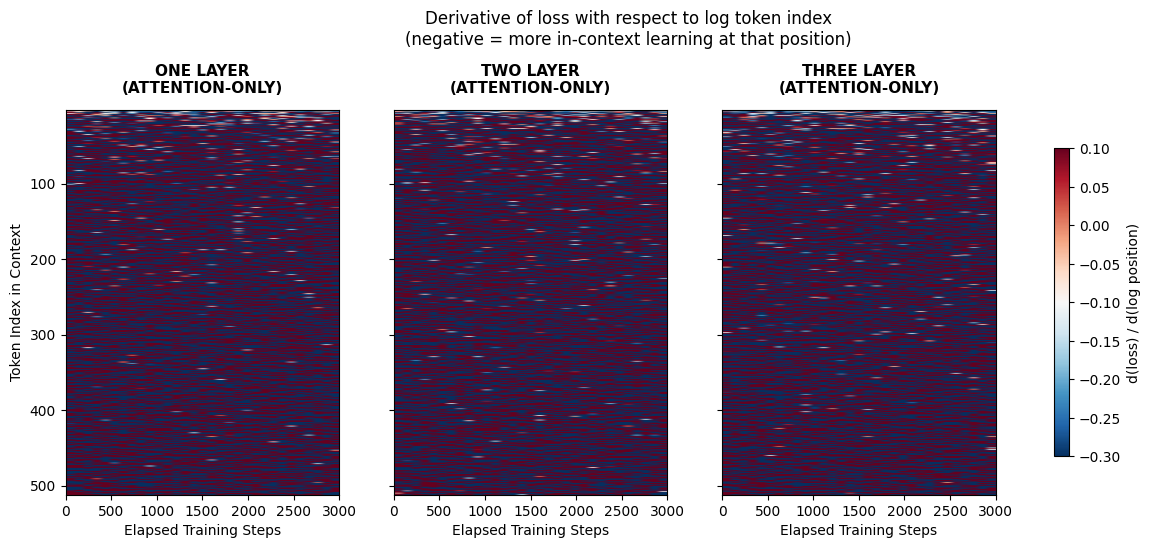

Saved /content/drive/MyDrive/sentinelbench_gpt2_results/derivative_heatmap_real_text.png

Compare qualitatively to the synthetic-task finding in Sections 1-10: if deeper (2-3 layer) models continue to improve with longer context after their own phase change, while the 1-layer model's improvement flattens early, that reproduces the original qualitative pattern -- multi-layer composition is what enables genuine in-context induction, not just single-layer pattern matching.


In [ ]:
def compute_derivative_heatmap(model, saved_params, cfg: RealTextConfig, eval_ids,
                                 n_eval_batches: int = 6, max_position: int = 512):
    """For each checkpoint, computes mean per-position loss over held-out text, then the
    discrete derivative of that loss curve with respect to log(position). Returns
    (steps_sorted, position_grid, derivative_matrix) where derivative_matrix has shape
    (len(position_grid), len(steps_sorted))."""
    steps_sorted = sorted(saved_params.keys())
    position_grid = np.arange(2, max_position + 1)  # start at 2: log(1)=0 is degenerate
    log_pos = np.log(position_grid)

    deriv_matrix = np.zeros((len(position_grid), len(steps_sorted)))

    rng = random.PRNGKey(999)
    for j, s in enumerate(steps_sorted):
        params = saved_params[s]
        losses_accum = np.zeros(cfg.seq_len)
        for _ in range(n_eval_batches):
            rng, sub = random.split(rng)
            batch = sample_real_text_batch(sub, eval_ids, cfg, cfg.batch_size)
            nll = per_position_loss(model, params, batch)  # (batch, seq_len)
            losses_accum += np.array(nll.mean(axis=0))
        mean_loss_by_pos = losses_accum / n_eval_batches  # (seq_len-1,), index 0 = position 1

        loss_at_positions = mean_loss_by_pos[position_grid - 1]  # position_grid is 1-indexed
        # discrete derivative d(loss)/d(log position) via central differences
        deriv = np.gradient(loss_at_positions, log_pos)
        deriv_matrix[:, j] = deriv

    return np.array(steps_sorted), position_grid, deriv_matrix


fig, axes = plt.subplots(1, 3, figsize=(15, 5), sharey=True)
titles = {1: "ONE LAYER\n(ATTENTION-ONLY)", 2: "TWO LAYER\n(ATTENTION-ONLY)",
          3: "THREE LAYER\n(ATTENTION-ONLY)"}

all_deriv_results = {}
for idx, n_layers in enumerate([1, 2, 3]):
    model, saved_params, _ = depth_scan_results[n_layers]
    steps_sorted, position_grid, deriv_matrix = compute_derivative_heatmap(
        model, saved_params, REAL_TEXT_CONFIG, pnp_eval_ids
    )
    all_deriv_results[n_layers] = (steps_sorted, position_grid, deriv_matrix)

    ax = axes[idx]
    im = ax.imshow(deriv_matrix, aspect="auto", origin="upper", cmap="RdBu_r",
                    vmin=-0.3, vmax=0.1,
                    extent=[steps_sorted[0], steps_sorted[-1], position_grid[-1], position_grid[0]])
    ax.set_title(titles[n_layers], fontsize=11, fontweight="bold", pad=12)
    ax.set_xlabel("Elapsed Training Steps")
    if idx == 0:
        ax.set_ylabel("Token Index in Context")

fig.suptitle("Derivative of loss with respect to log token index\n"
             "(negative = more in-context learning at that position)", fontsize=12, y=1.08)
fig.colorbar(im, ax=axes.tolist(), label="d(loss) / d(log position)", shrink=0.8)
deriv_fig_path = os.path.join(RESULTS_DIR, "derivative_heatmap_real_text.png")
plt.savefig(deriv_fig_path, dpi=150, bbox_inches="tight")
plt.show()
print("Saved", deriv_fig_path)
print("\nCompare qualitatively to the synthetic-task finding in Sections 1-10: if deeper "
      "(2-3 layer) models continue to improve with longer context after their own phase change, "
      "while the 1-layer model's improvement flattens early, that reproduces the original "
      "qualitative pattern -- multi-layer composition is what enables genuine in-context "
      "induction, not just single-layer pattern matching.")


### 11.5 Real-text qualitative example: what the phase change looks like on an actual passage

This is the most intuitive of the three additions. We take the 3-layer model, pick an early
checkpoint (before its phase change) and a late checkpoint (after), and run both on a real
*Pride and Prejudice* passage. For each token, we color it by how much the **later** checkpoint's
prediction improved or worsened relative to the **earlier** one:

- **Red**: the later checkpoint predicts this token much better (lower loss) — typically repeated
  names and phrases the model can now copy via induction (e.g. a second occurrence of "Mrs.
  Bennet" or "Mr. Darcy").
- **Green**: the later checkpoint predicts this token *worse* — typically cases where the same
  preceding context was earlier followed by a different continuation, and the model now
  overzealously expects a repeat.


In [ ]:
def per_token_loss_delta(model, params_before, params_after, token_ids):
    """Returns (tokens_str_list, loss_before, loss_after, delta) for a single sequence,
    where delta = loss_before - loss_after (positive = later checkpoint is better)."""
    tokens = jnp.array(token_ids)[None, :]
    loss_before = np.array(per_position_loss(model, params_before, tokens))[0]
    loss_after = np.array(per_position_loss(model, params_after, tokens))[0]
    delta = loss_before - loss_after
    char_list = [id_to_char[int(i)] for i in token_ids[1:]]  # predictions start at position 1
    return char_list, loss_before, loss_after, delta


def render_colored_text(chars, deltas, path, title, threshold=0.15):
    """Render characters with a red/teal background based on prediction-quality delta,
    matching the qualitative style of the original figure. Saves to `path`."""
    fig, ax = plt.subplots(figsize=(11, 6))
    ax.axis("off")
    ax.set_title(title, fontsize=12, loc="left", pad=20)

    x, y = 0.0, 0.90
    line_height = 0.045
    max_width = 0.98
    for ch, d in zip(chars, deltas):
        if d > threshold:
            color = "#f6a9a0"   # red: much better after
        elif d < -threshold:
            color = "#9fd6cf"   # teal: worse after
        else:
            color = "none"
        w = 0.011 if ch != " " else 0.008
        if ch == "\n":
            x = 0.0
            y -= line_height
            continue
        if x + w > max_width:
            x = 0.0
            y -= line_height
        if color != "none":
            ax.add_patch(plt.Rectangle((x, y - 0.03), w, 0.04, transform=ax.transAxes,
                                        facecolor=color, edgecolor="none", zorder=0))
        ax.text(x, y, ch, transform=ax.transAxes, fontsize=9, family="monospace", va="bottom")
        x += w
    plt.tight_layout()
    plt.savefig(path, dpi=150, bbox_inches="tight")
    plt.show()


# Use the 3-layer model; compare its earliest checkpoint to its final checkpoint.
model_3l, saved_params_3l, _ = depth_scan_results[3]
steps_3l = sorted(saved_params_3l.keys())
before_step, after_step = steps_3l[0], steps_3l[-1]
params_before = saved_params_3l[before_step]
params_after = saved_params_3l[after_step]

# Pick a passage from the held-out eval region so it wasn't directly optimized against.
excerpt_ids = pnp_eval_ids[: REAL_TEXT_CONFIG.seq_len]
chars, loss_before, loss_after, delta = per_token_loss_delta(
    model_3l, params_before, params_after, excerpt_ids
)

render_colored_text(
    chars[:600], delta[:600],
    os.path.join(RESULTS_DIR, "real_text_qualitative.png"),
    title=f"3-layer model: step {before_step} -> step {after_step} per-token prediction change\n"
          f"(red = better predicted after training, teal = worse)",
)

print(f"\nMean loss at step {before_step}: {float(loss_before.mean()):.3f}")
print(f"Mean loss at step {after_step}:  {float(loss_after.mean()):.3f}")
print(f"Fraction of positions with meaningfully better prediction (delta > 0.15): "
      f"{float((delta > 0.15).mean()):.3f}")
print(f"Fraction of positions with meaningfully worse prediction (delta < -0.15): "
      f"{float((delta < -0.15).mean()):.3f}")


<p align="left">
  <img src="../figures/real_text_qualitative.png" width="1000">
</p>


### 11.6 What this adds to the main finding

Sections 1–10 establish the central result in a controlled synthetic setting: behavioural performance can stabilize substantially earlier than a causal mechanistic measurement of the same learned capability. The real-text experiments extend this analysis beyond the synthetic task, showing that related induction-head signatures can also be observed in a smaller character-level language model trained on natural text.

These experiments do not establish that the synthetic and real-text models learn identical mechanisms, nor do they provide a causal account of the real-text model. Instead, they provide a complementary check that the phenomena motivating the synthetic experiments are not confined to an artificial token-repetition task.

Taken together, the results support a deliberately narrow conclusion: stable behavioural performance does not necessarily imply that a mechanistic measurement has stabilized on the same timeline. Behaviour and mechanism can therefore provide meaningfully different views of capability development during training.
